#2 IMPORT LIBRARIES

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import minimize
import warnings

warnings.filterwarnings("ignore")

#3 PROJECT PARAMETERS

In [6]:
# Project Parameters

START_DATE = "2007-01-01"
END_DATE = "2026-09-30"

TRADING_DAYS = 252

MIN_ASSETS = 4
MAX_ASSETS = 8

N_PORTFOLIOS = 10000

RISK_FREE_RATE = 0.06

print("Project parameters set successfully")

Project parameters set successfully


#4 ASSET UNIVERSE 

In [7]:
# Asset Universe

assets = [
    "S&P 500",
    "Nasdaq",
    "Nikkei",
    "BSE Sensex",
    "S&P BSE Mid Cap",
    "S&P BSE Small Cap",
    "FTSE 100",
    "Hang Seng",
    "S&P/ASX 200",
    "Gold",
    "Brent Crude",
    "US 10-Year Benchmark",
    "India 10-Year Benchmark",
    "Fixed Deposit India"
]

print("Number of assets:", len(assets))
print("\nAsset Universe:")
for i, asset in enumerate(assets, start=1):
    print(i, "-", asset)

Number of assets: 14

Asset Universe:
1 - S&P 500
2 - Nasdaq
3 - Nikkei
4 - BSE Sensex
5 - S&P BSE Mid Cap
6 - S&P BSE Small Cap
7 - FTSE 100
8 - Hang Seng
9 - S&P/ASX 200
10 - Gold
11 - Brent Crude
12 - US 10-Year Benchmark
13 - India 10-Year Benchmark
14 - Fixed Deposit India


#5 Historical Data Mapping 

In [8]:
# Historical data ticker mapping

market_tickers = {
    "S&P 500": "^GSPC",
    "Nasdaq": "^IXIC",
    "Nikkei": "^N225",
    "BSE Sensex": "^BSESN",
    "FTSE 100": "^FTSE",
    "Hang Seng": "^HSI",
    "S&P/ASX 200": "^AXJO",
    "Gold": "GC=F",
    "Brent Crude": "BZ=F"
}

print("Market data assets:", len(market_tickers))

for asset, ticker in market_tickers.items():
    print(f"{asset} → {ticker}")

Market data assets: 9
S&P 500 → ^GSPC
Nasdaq → ^IXIC
Nikkei → ^N225
BSE Sensex → ^BSESN
FTSE 100 → ^FTSE
Hang Seng → ^HSI
S&P/ASX 200 → ^AXJO
Gold → GC=F
Brent Crude → BZ=F


#6 Download Historical Market Data 

In [9]:
# Download historical data for the 9 market assets

raw_data = yf.download(
    list(market_tickers.values()),
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False
)

print("Data downloaded successfully!")
print("Shape of downloaded data:", raw_data.shape)

Data downloaded successfully!
Shape of downloaded data: (5141, 45)


In [10]:
raw_data.head()

Price      Close                                                      \
Ticker      BZ=F        GC=F        ^AXJO        ^BSESN        ^FTSE   
Date                                                                   
2007-01-02   NaN  635.200012  5670.200195  13942.240234  6310.899902   
2007-01-03   NaN  627.099976  5649.399902  14014.919922  6319.000000   
2007-01-04   NaN  623.900024  5584.799805  13871.709961  6287.000000   
2007-01-05   NaN  604.900024  5572.000000  13860.519531  6220.100098   
2007-01-08   NaN  607.500000  5502.000000  13652.150391  6194.200195   

Price                                                            High  ...  \
Ticker            ^GSPC          ^HSI        ^IXIC         ^N225 BZ=F  ...   
Date                                                                   ...   
2007-01-02          NaN  20310.179688          NaN           NaN  NaN  ...   
2007-01-03  1416.599976  20413.390625  2423.159912           NaN  NaN  ...   
2007-01-04  1418.339966  20025.580078  2453.429932  17353.669922  NaN  ...   
2007-01-05  1409.709961  20211.279297  2434.250000  17091.589844  NaN  ...   
2007-01-08  1412.839966  20029.660156  2438.199951           NaN  NaN  ...   

Price               Open Volume                                       \
Ticker             ^N225   BZ=F    GC=F ^AXJO   ^BSESN         ^FTSE   
Date                                                                   
2007-01-02           NaN    NaN    17.0   0.0   9600.0  1.074946e+09   
2007-01-03           NaN    NaN    38.0   0.0  11600.0  1.606893e+09   
2007-01-04  17322.500000    NaN     4.0   0.0  14600.0  1.902876e+09   
2007-01-05  17315.539062    NaN   531.0   0.0  13200.0  1.622439e+09   
2007-01-08           NaN    NaN  1000.0   0.0  11600.0  1.326701e+09   

Price                                                              
Ticker             ^GSPC          ^HSI         ^IXIC        ^N225  
Date                                                               
2007-01-02           NaN  1.264600e+09           NaN          NaN  
2007-01-03  3.429160e+09  1.674000e+09  2.435280e+09          NaN  
2007-01-04  3.004460e+09  2.130500e+09  2.104210e+09   80100000.0  
2007-01-05  2.919400e+09  1.959100e+09  2.060360e+09  158600000.0  
2007-01-08  2.763340e+09  1.438600e+09  1.905620e+09          NaN  

[5 rows x 45 columns]

In [11]:
raw_data.tail()

Price            Close                                                        \
Ticker            BZ=F         GC=F        ^AXJO        ^BSESN         ^FTSE   
Date                                                                           
2026-09-23  103.080002  4318.399902  8765.299805  74828.250000  10705.299805   
2026-09-24  106.599998  4298.000000  8702.000000  73580.539062  10680.000000   
2026-09-25  104.320000  4321.200195  8665.000000  73895.742188  10695.299805   
2026-09-28  105.279999  4168.399902  8679.700195  72771.718750  10684.900391   
2026-09-29  102.589996  4179.700195  8709.299805  72529.070312  10636.700195   

Price                                                                    High  \
Ticker            ^GSPC          ^HSI         ^IXIC         ^N225        BZ=F   
Date                                                                            
2026-09-23  7706.029785  24834.119141  26936.039062           NaN  103.860001   
2026-09-24  7704.129883  24761.130859  26939.369141  65513.988281  108.230003   
2026-09-25  7743.410156  24510.089844  27068.720703  66364.203125  106.750000   
2026-09-28  7683.689941  24642.509766  26820.380859  65877.617188  108.809998   
2026-09-29  7670.839844  24523.570312  26797.539062  65481.269531  107.610001   

Price       ...          Open   Volume                               \
Ticker      ...         ^N225     BZ=F      GC=F     ^AXJO   ^BSESN   
Date        ...                                                       
2026-09-23  ...           NaN  51561.0  143873.0  699100.0  11700.0   
2026-09-24  ...  65476.441406  57116.0  164814.0  726100.0  21100.0   
2026-09-25  ...  65639.617188  28791.0  140092.0  589900.0  31900.0   
2026-09-28  ...  66505.937500  15803.0  229031.0  708100.0  14200.0   
2026-09-29  ...  65557.992188  11974.0  149747.0  627400.0  10600.0   

Price                                                                           
Ticker            ^FTSE         ^GSPC          ^HSI         ^IXIC        ^N225  
Date                                                                            
2026-09-23  642518600.0  5.110910e+09  2.029600e+09  8.491740e+09          NaN  
2026-09-24  971886900.0  5.316390e+09  1.927300e+09  8.078820e+09  175000000.0  
2026-09-25  701463900.0  4.499180e+09  1.343800e+09  7.275260e+09  148900000.0  
2026-09-28  536195200.0  5.129710e+09  2.328900e+09  7.030730e+09  161800000.0  
2026-09-29  741634900.0  5.023590e+09  2.997600e+09  7.097250e+09  170800000.0  

[5 rows x 45 columns]

In [12]:
raw_data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5141 entries, 2007-01-02 to 2026-09-29
Data columns (total 45 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   (Close, BZ=F)     4771 non-null   float64
 1   (Close, GC=F)     4967 non-null   float64
 2   (Close, ^AXJO)    4987 non-null   float64
 3   (Close, ^BSESN)   4850 non-null   float64
 4   (Close, ^FTSE)    4987 non-null   float64
 5   (Close, ^GSPC)    4966 non-null   float64
 6   (Close, ^HSI)     4861 non-null   float64
 7   (Close, ^IXIC)    4966 non-null   float64
 8   (Close, ^N225)    4824 non-null   float64
 9   (High, BZ=F)      4771 non-null   float64
 10  (High, GC=F)      4967 non-null   float64
 11  (High, ^AXJO)     4987 non-null   float64
 12  (High, ^BSESN)    4850 non-null   float64
 13  (High, ^FTSE)     4987 non-null   float64
 14  (High, ^GSPC)     4966 non-null   float64
 15  (High, ^HSI)      4861 non-null   float64
 16  (High, ^IXIC)     4966 n

In [13]:
print("First date:", raw_data.index.min())
print("Last date:", raw_data.index.max())
print("Number of observations:", len(raw_data))

First date: 2007-01-02 00:00:00
Last date: 2026-09-29 00:00:00
Number of observations: 5141


In [14]:
# Extract only closing prices

prices = raw_data["Close"].copy()

print("Number of assets:", prices.shape[1])
print("Number of observations:", prices.shape[0])

prices.head()

Number of assets: 9
Number of observations: 5141


Ticker,BZ=F,GC=F,^AXJO,^BSESN,^FTSE,^GSPC,^HSI,^IXIC,^N225
Date,,,,,,,,,
2007-01-02,NaN,635.200012,5670.200195,13942.240234,6310.899902,NaN,20310.179688,NaN,NaN
2007-01-03,NaN,627.099976,5649.399902,14014.919922,6319.000000,1416.599976,20413.390625,2423.159912,NaN
2007-01-04,NaN,623.900024,5584.799805,13871.709961,6287.000000,1418.339966,20025.580078,2453.429932,17353.669922
2007-01-05,NaN,604.900024,5572.000000,13860.519531,6220.100098,1409.709961,20211.279297,2434.250000,17091.589844
2007-01-08,NaN,607.500000,5502.000000,13652.150391,6194.200195,1412.839966,20029.660156,2438.199951,NaN


In [15]:
# Rename ticker symbols to asset names

reverse_tickers = {
    "^GSPC": "S&P 500",
    "^IXIC": "Nasdaq",
    "^N225": "Nikkei",
    "^BSESN": "BSE Sensex",
    "^FTSE": "FTSE 100",
    "^HSI": "Hang Seng",
    "^AXJO": "S&P/ASX 200",
    "GC=F": "Gold",
    "BZ=F": "Brent Crude"
}

prices.rename(columns=reverse_tickers, inplace=True)

prices.head()

Ticker,Brent Crude,Gold,S&P/ASX 200,BSE Sensex,FTSE 100,S&P 500,Hang Seng,Nasdaq,Nikkei
Date,,,,,,,,,
2007-01-02,NaN,635.200012,5670.200195,13942.240234,6310.899902,NaN,20310.179688,NaN,NaN
2007-01-03,NaN,627.099976,5649.399902,14014.919922,6319.000000,1416.599976,20413.390625,2423.159912,NaN
2007-01-04,NaN,623.900024,5584.799805,13871.709961,6287.000000,1418.339966,20025.580078,2453.429932,17353.669922
2007-01-05,NaN,604.900024,5572.000000,13860.519531,6220.100098,1409.709961,20211.279297,2434.250000,17091.589844
2007-01-08,NaN,607.500000,5502.000000,13652.150391,6194.200195,1412.839966,20029.660156,2438.199951,NaN


In [16]:
# Check missing values

missing_values = prices.isnull().sum()

missing_values.sort_values(ascending=False)

Ticker
Brent Crude    370
Nikkei         317
BSE Sensex     291
Hang Seng      280
S&P 500        175
Nasdaq         175
Gold           174
S&P/ASX 200    154
FTSE 100       154
dtype: int64

In [17]:
# Missing values as percentage of total observations

missing_percentage = (
    prices.isnull().sum()
    / len(prices)
    * 100
)

missing_percentage.sort_values(ascending=False)

Ticker
Brent Crude    7.197043
Nikkei         6.166116
BSE Sensex     5.660377
Hang Seng      5.446411
S&P 500        3.404007
Nasdaq         3.404007
Gold           3.384556
S&P/ASX 200    2.995526
FTSE 100       2.995526
dtype: float64

In [18]:
# Check the first and last available date for each asset

for column in prices.columns:
    first_date = prices[column].first_valid_index()
    last_date = prices[column].last_valid_index()
    
    print(
        f"{column}: "
        f"{first_date.date()} → {last_date.date()}"
    )

Brent Crude: 2007-07-30 → 2026-09-29
Gold: 2007-01-02 → 2026-09-29
S&P/ASX 200: 2007-01-02 → 2026-09-29
BSE Sensex: 2007-01-02 → 2026-09-29
FTSE 100: 2007-01-02 → 2026-09-29
S&P 500: 2007-01-03 → 2026-09-29
Hang Seng: 2007-01-02 → 2026-09-29
Nasdaq: 2007-01-03 → 2026-09-29
Nikkei: 2007-01-04 → 2026-09-29


In [19]:
# US 10-Year Treasury proxy

us10y_data = yf.download(
    "IEF",
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False
)

us10y_price = us10y_data["Close"].copy()

print("US 10-Year Treasury proxy downloaded successfully")
print("Start date:", us10y_price.index.min())
print("End date:", us10y_price.index.max())
print("Number of observations:", len(us10y_price))

US 10-Year Treasury proxy downloaded successfully
Start date: 2007-01-03 00:00:00
End date: 2026-09-29 00:00:00
Number of observations: 4966


In [20]:
us10y_price.head()

Ticker,IEF
Date,
2007-01-03,49.789146
2007-01-04,49.969810
2007-01-05,49.807194
2007-01-08,49.843288
2007-01-09,49.831264


In [21]:
# Fixed Deposit India
# Assumption: constant annual return of 6.5%

FD_ANNUAL_RATE = 0.065

FD_DAILY_RETURN = (1 + FD_ANNUAL_RATE) ** (1 / 365) - 1

print("FD annual return:", FD_ANNUAL_RATE)
print("FD daily return:", FD_DAILY_RETURN)

FD annual return: 0.065
FD daily return: 0.00017254858112680793


In [22]:
# Load Bloomberg datasets

midcap_tri = pd.read_excel(
    r"C:\Users\Dell\Desktop\sapm dataset\BSE MIDCAP TRI.xlsx"
)

smallcap_tri = pd.read_excel(
    r"C:\Users\Dell\Desktop\sapm dataset\BSE SMALLCAP TRI.xlsx"
)

india_10y = pd.read_excel(
    r"C:\Users\Dell\Desktop\sapm dataset\INDIA 10 Y BOND.xlsx"
)

us_10y = pd.read_excel(
    r"C:\Users\Dell\Desktop\sapm dataset\US 10 Y BOND.xlsx"
)

print("BSE MidCap:", midcap_tri.shape)
print("BSE SmallCap:", smallcap_tri.shape)
print("India 10Y:", india_10y.shape)
print("US 10Y:", us_10y.shape)

BSE MidCap: (1050, 3)
BSE SmallCap: (1050, 3)
India 10Y: (1050, 3)
US 10Y: (1050, 3)


In [23]:
# Check the column names in all four Bloomberg datasets

print("BSE MidCap columns:")
print(midcap_tri.columns.tolist())

print("\nBSE SmallCap columns:")
print(smallcap_tri.columns.tolist())

print("\nIndia 10Y columns:")
print(india_10y.columns.tolist())

print("\nUS 10Y columns:")
print(us_10y.columns.tolist())

BSE MidCap columns:
['Security', 'BSEMIDT Index', 'Unnamed: 2']

BSE SmallCap columns:
['Security', 'BSESMLT Index', 'Unnamed: 2']

India 10Y columns:
['Security', 'IGTR10YR Index', 'Unnamed: 2']

US 10Y columns:
['Security', 'SPBDU1BT Index', 'Unnamed: 2']


In [24]:
# ==========================================
# LOAD BLOOMBERG DATASETS
# ==========================================

midcap_tri = pd.read_excel(
    r"C:\Users\Dell\Desktop\sapm dataset\BSE MIDCAP TRI.xlsx",
    skiprows=6
)

smallcap_tri = pd.read_excel(
    r"C:\Users\Dell\Desktop\sapm dataset\BSE SMALLCAP TRI.xlsx",
    skiprows=6
)

india_10y = pd.read_excel(
    r"C:\Users\Dell\Desktop\sapm dataset\INDIA 10 Y BOND.xlsx",
    skiprows=6
)

us_10y = pd.read_excel(
    r"C:\Users\Dell\Desktop\sapm dataset\US 10 Y BOND.xlsx",
    skiprows=6
)

print("BSE MidCap:", midcap_tri.shape)
print("BSE SmallCap:", smallcap_tri.shape)
print("India 10Y:", india_10y.shape)
print("US 10Y:", us_10y.shape)

print("\nBSE MidCap columns:")
print(midcap_tri.columns.tolist())

print("\nBSE SmallCap columns:")
print(smallcap_tri.columns.tolist())

print("\nIndia 10Y columns:")
print(india_10y.columns.tolist())

print("\nUS 10Y columns:")
print(us_10y.columns.tolist())

BSE MidCap: (1044, 3)
BSE SmallCap: (1044, 3)
India 10Y: (1044, 3)
US 10Y: (1044, 3)

BSE MidCap columns:
['Date', 'PX_LAST', 'PX_BID']

BSE SmallCap columns:
['Date', 'PX_LAST', 'PX_BID']

India 10Y columns:
['Date', 'PX_LAST', 'PX_BID']

US 10Y columns:
['Date', 'PX_LAST', 'CHG_PCT_1D']


In [25]:
# ==========================================
# CHECK BLOOMBERG DATA
# ==========================================

datasets = {
    "BSE MidCap": midcap_tri,
    "BSE SmallCap": smallcap_tri,
    "India 10Y": india_10y,
    "US 10Y": us_10y
}

for name, df in datasets.items():
    print("\n" + "="*50)
    print(name)
    print("="*50)
    print("Start:", df["Date"].min())
    print("End:", df["Date"].max())
    print("\nFirst 5 observations:")
    print(df[["Date", "PX_LAST"]].head())


BSE MidCap
Start: 2006-10-06 00:00:00
End: 2026-10-02 00:00:00

First 5 observations:
        Date   PX_LAST
0 2026-10-02  58121.93
1 2026-09-25  60318.01
2 2026-09-18  61451.68
3 2026-09-11  61570.18
4 2026-09-04  62463.56

BSE SmallCap
Start: 2006-10-08 00:00:00
End: 2026-10-04 00:00:00

First 5 observations:
        Date   PX_LAST
0 2026-10-04  71097.35
1 2026-09-27  73024.29
2 2026-09-20  73005.48
3 2026-09-13  73329.54
4 2026-09-06  73443.26

India 10Y
Start: 2006-10-06 00:00:00
End: 2026-10-02 00:00:00

First 5 observations:
        Date  PX_LAST
0 2026-10-02  576.788
1 2026-09-25  579.648
2 2026-09-18  580.850
3 2026-09-11  581.851
4 2026-09-04  583.482

US 10Y
Start: 2006-10-06 00:00:00
End: 2026-10-02 00:00:00

First 5 observations:
        Date   PX_LAST
0 2026-10-02  508.3347
1 2026-09-25  512.6233
2 2026-09-18  518.2203
3 2026-09-11  519.0611
4 2026-09-04  526.4859


In [26]:
# ==========================================
# CREATE CLEAN WEEKLY RETURN SERIES
# ==========================================

# Keep Date and PX_LAST only
midcap_returns = midcap_tri[["Date", "PX_LAST"]].copy()
smallcap_returns = smallcap_tri[["Date", "PX_LAST"]].copy()
india10y_returns = india_10y[["Date", "PX_LAST"]].copy()
us10y_returns = us_10y[["Date", "PX_LAST"]].copy()

# Rename PX_LAST to asset names
midcap_returns.rename(columns={"PX_LAST": "S&P BSE Mid Cap"}, inplace=True)
smallcap_returns.rename(columns={"PX_LAST": "S&P BSE Small Cap"}, inplace=True)
india10y_returns.rename(columns={"PX_LAST": "India 10-Year Benchmark"}, inplace=True)
us10y_returns.rename(columns={"PX_LAST": "US 10-Year Benchmark"}, inplace=True)

# Sort by date
midcap_returns = midcap_returns.sort_values("Date")
smallcap_returns = smallcap_returns.sort_values("Date")
india10y_returns = india10y_returns.sort_values("Date")
us10y_returns = us10y_returns.sort_values("Date")

# Calculate weekly returns
midcap_returns["Return"] = midcap_returns["S&P BSE Mid Cap"].pct_change()
smallcap_returns["Return"] = smallcap_returns["S&P BSE Small Cap"].pct_change()
india10y_returns["Return"] = india10y_returns["India 10-Year Benchmark"].pct_change()
us10y_returns["Return"] = us10y_returns["US 10-Year Benchmark"].pct_change()

print("Mid Cap:")
print(midcap_returns.head())

print("\nSmall Cap:")
print(smallcap_returns.head())

print("\nIndia 10Y:")
print(india10y_returns.head())

print("\nUS 10Y:")
print(us10y_returns.head())

Mid Cap:
           Date  S&P BSE Mid Cap    Return
1043 2006-10-06          5292.70       NaN
1042 2006-10-13          5316.96  0.004584
1041 2006-10-20          5331.89  0.002808
1040 2006-10-27          5426.97  0.017832
1039 2006-11-03          5526.94  0.018421

Small Cap:
           Date  S&P BSE Small Cap    Return
1043 2006-10-08            6371.49       NaN
1042 2006-10-15            6460.00  0.013892
1041 2006-10-22            6528.80  0.010650
1040 2006-10-29            6564.71  0.005500
1039 2006-11-05            6520.22 -0.006777

India 10Y:
           Date  India 10-Year Benchmark    Return
1043 2006-10-06                  175.542       NaN
1042 2006-10-13                  175.234 -0.001755
1041 2006-10-20                  175.458  0.001278
1040 2006-10-27                  176.175  0.004086
1039 2006-11-03                  176.010 -0.000937

US 10Y:
           Date  US 10-Year Benchmark    Return
1043 2006-10-06              297.0175       NaN
1042 2006-10-13             

In [27]:
# ==========================================
# CONVERT YAHOO DAILY DATA TO WEEKLY DATA
# ==========================================

# Convert daily prices to weekly prices
# We take the last available market price of each week

weekly_prices = prices.resample("W-FRI").last()

# Calculate weekly returns
weekly_returns = weekly_prices.pct_change()

# Remove the first row because it has no previous week
weekly_returns = weekly_returns.dropna(how="all")

print("Weekly price data shape:", weekly_prices.shape)
print("Weekly return data shape:", weekly_returns.shape)

print("\nWeekly returns:")
print(weekly_returns.head())

Weekly price data shape: (1031, 9)
Weekly return data shape: (1030, 9)

Weekly returns:
Ticker      Brent Crude      Gold  S&P/ASX 200  BSE Sensex  FTSE 100  \
Date                                                                   
2007-01-12          NaN  0.034055     0.011988    0.014142  0.003039   
2007-01-19          NaN  0.015987     0.006083    0.008977 -0.000288   
2007-01-26          NaN  0.014162     0.017063    0.007052 -0.001475   
2007-02-02          NaN  0.002638     0.010676    0.008475  0.013311   
2007-02-09          NaN  0.032962     0.016411    0.009382  0.011393   

Ticker       S&P 500  Hang Seng    Nasdaq    Nikkei  
Date                                                 
2007-01-12  0.014911  -0.029581  0.028169 -0.002023  
2007-01-19 -0.000161   0.036419 -0.020581  0.014858  
2007-01-26 -0.005816  -0.002292 -0.006454  0.006441  
2007-02-02  0.018429   0.013932  0.016584  0.007185  
2007-02-09 -0.007132   0.005543 -0.006487 -0.002438  


In [28]:
# ==========================================
# CREATE FINAL 14-ASSET WEEKLY DATASET
# ==========================================

# ----- 1. Bloomberg weekly prices -----

bloomberg_prices = pd.DataFrame({
    "S&P BSE Mid Cap": midcap_tri.set_index("Date")["PX_LAST"],
    "S&P BSE Small Cap": smallcap_tri.set_index("Date")["PX_LAST"],
    "India 10-Year Benchmark": india_10y.set_index("Date")["PX_LAST"],
    "US 10-Year Benchmark": us_10y.set_index("Date")["PX_LAST"]
})

# Align Bloomberg data to Friday
bloomberg_weekly_prices = bloomberg_prices.resample("W-FRI").last()

# Bloomberg weekly returns
bloomberg_weekly_returns = bloomberg_weekly_prices.pct_change()


# ----- 2. Yahoo weekly returns -----

yahoo_weekly_returns = weekly_returns.copy()


# ----- 3. Combine Yahoo + Bloomberg -----

master_returns = pd.concat(
    [
        yahoo_weekly_returns,
        bloomberg_weekly_returns
    ],
    axis=1
)


# ----- 4. Add Fixed Deposit -----

FD_WEEKLY_RETURN = (1 + FD_ANNUAL_RATE) ** (7 / 365) - 1

master_returns["Fixed Deposit India"] = FD_WEEKLY_RETURN


# ----- 5. Keep only our 14 required assets -----

asset_order = [
    "S&P 500",
    "Nasdaq",
    "Nikkei",
    "BSE Sensex",
    "S&P BSE Mid Cap",
    "S&P BSE Small Cap",
    "FTSE 100",
    "Hang Seng",
    "S&P/ASX 200",
    "Gold",
    "Brent Crude",
    "US 10-Year Benchmark",
    "India 10-Year Benchmark",
    "Fixed Deposit India"
]

master_returns = master_returns[asset_order]


# ----- 6. Check final dataset -----

print("FINAL MASTER DATASET")
print("====================")

print("Number of assets:", len(master_returns.columns))
print("Number of weeks:", len(master_returns))

print("\nAssets:")
for i, asset in enumerate(master_returns.columns, start=1):
    print(i, "-", asset)

print("\nDate range:")
print(master_returns.index.min(), "→", master_returns.index.max())

print("\nMissing values:")
print(master_returns.isnull().sum())

FINAL MASTER DATASET
Number of assets: 14
Number of weeks: 1045

Assets:
1 - S&P 500
2 - Nasdaq
3 - Nikkei
4 - BSE Sensex
5 - S&P BSE Mid Cap
6 - S&P BSE Small Cap
7 - FTSE 100
8 - Hang Seng
9 - S&P/ASX 200
10 - Gold
11 - Brent Crude
12 - US 10-Year Benchmark
13 - India 10-Year Benchmark
14 - Fixed Deposit India

Date range:
2006-10-06 00:00:00 → 2026-10-09 00:00:00

Missing values:
S&P 500                    15
Nasdaq                     15
Nikkei                     15
BSE Sensex                 15
S&P BSE Mid Cap             1
S&P BSE Small Cap           2
FTSE 100                   15
Hang Seng                  15
S&P/ASX 200                15
Gold                       15
Brent Crude                45
US 10-Year Benchmark        1
India 10-Year Benchmark     1
Fixed Deposit India         0
dtype: int64


In [29]:
# ==========================================
# FINAL DATA CLEANING
# ==========================================

# Keep only weeks where all 14 assets have data
master_returns_clean = master_returns.dropna().copy()

print("Before cleaning:", len(master_returns), "weeks")
print("After cleaning:", len(master_returns_clean), "weeks")

print("\nFinal date range:")
print(
    master_returns_clean.index.min(),
    "→",
    master_returns_clean.index.max()
)

print("\nRemaining missing values:")
print(master_returns_clean.isnull().sum())

print("\nFinal dataset shape:")
print(master_returns_clean.shape)

Before cleaning: 1045 weeks
After cleaning: 1000 weeks

Final date range:
2007-08-10 00:00:00 → 2026-10-02 00:00:00

Remaining missing values:
S&P 500                    0
Nasdaq                     0
Nikkei                     0
BSE Sensex                 0
S&P BSE Mid Cap            0
S&P BSE Small Cap          0
FTSE 100                   0
Hang Seng                  0
S&P/ASX 200                0
Gold                       0
Brent Crude                0
US 10-Year Benchmark       0
India 10-Year Benchmark    0
Fixed Deposit India        0
dtype: int64

Final dataset shape:
(1000, 14)


In [30]:
# ==========================================
# ANNUALIZED RETURN AND RISK
# ==========================================

# Annualized weekly return
annual_return = (1 + master_returns_clean.mean()) ** 52 - 1

# Annualized volatility
annual_volatility = master_returns_clean.std() * np.sqrt(52)

# Create summary table
asset_statistics = pd.DataFrame({
    "Annual Return": annual_return,
    "Annual Volatility": annual_volatility
})

# Convert to percentage
asset_statistics["Annual Return %"] = asset_statistics["Annual Return"] * 100
asset_statistics["Annual Volatility %"] = asset_statistics["Annual Volatility"] * 100

asset_statistics = asset_statistics[
    ["Annual Return %", "Annual Volatility %"]
]

print(asset_statistics.round(2))

                         Annual Return %  Annual Volatility %
S&P 500                            10.93                18.06
Nasdaq                             15.49                20.42
Nikkei                              9.93                21.98
BSE Sensex                         10.57                19.48
S&P BSE Mid Cap                    14.66                22.13
S&P BSE Small Cap                  15.87                25.59
FTSE 100                            4.37                17.12
Hang Seng                           2.94                22.16
S&P/ASX 200                         3.23                15.79
Gold                               11.70                17.70
Brent Crude                         8.94                37.21
US 10-Year Benchmark                2.93                 7.52
India 10-Year Benchmark             6.32                 6.00
Fixed Deposit India                 6.48                 0.00


In [31]:
# ==========================================
# CORRELATION MATRIX
# ==========================================

correlation_matrix = master_returns_clean.corr()

print("Correlation Matrix:")
print(correlation_matrix.round(2))

Correlation Matrix:
                         S&P 500  Nasdaq  Nikkei  BSE Sensex  S&P BSE Mid Cap  \
S&P 500                     1.00    0.95    0.64        0.54             0.42   
Nasdaq                      0.95    1.00    0.62        0.52             0.41   
Nikkei                      0.64    0.62    1.00        0.52             0.42   
BSE Sensex                  0.54    0.52    0.52        1.00             0.84   
S&P BSE Mid Cap             0.42    0.41    0.42        0.84             1.00   
S&P BSE Small Cap          -0.02    0.00    0.03        0.06             0.11   
FTSE 100                    0.76    0.67    0.61        0.56             0.45   
Hang Seng                   0.51    0.50    0.57        0.56             0.46   
S&P/ASX 200                 0.67    0.63    0.63        0.56             0.46   
Gold                        0.08    0.08   -0.02        0.10             0.07   
Brent Crude                 0.30    0.25    0.19        0.19             0.18   
US 10-Ye

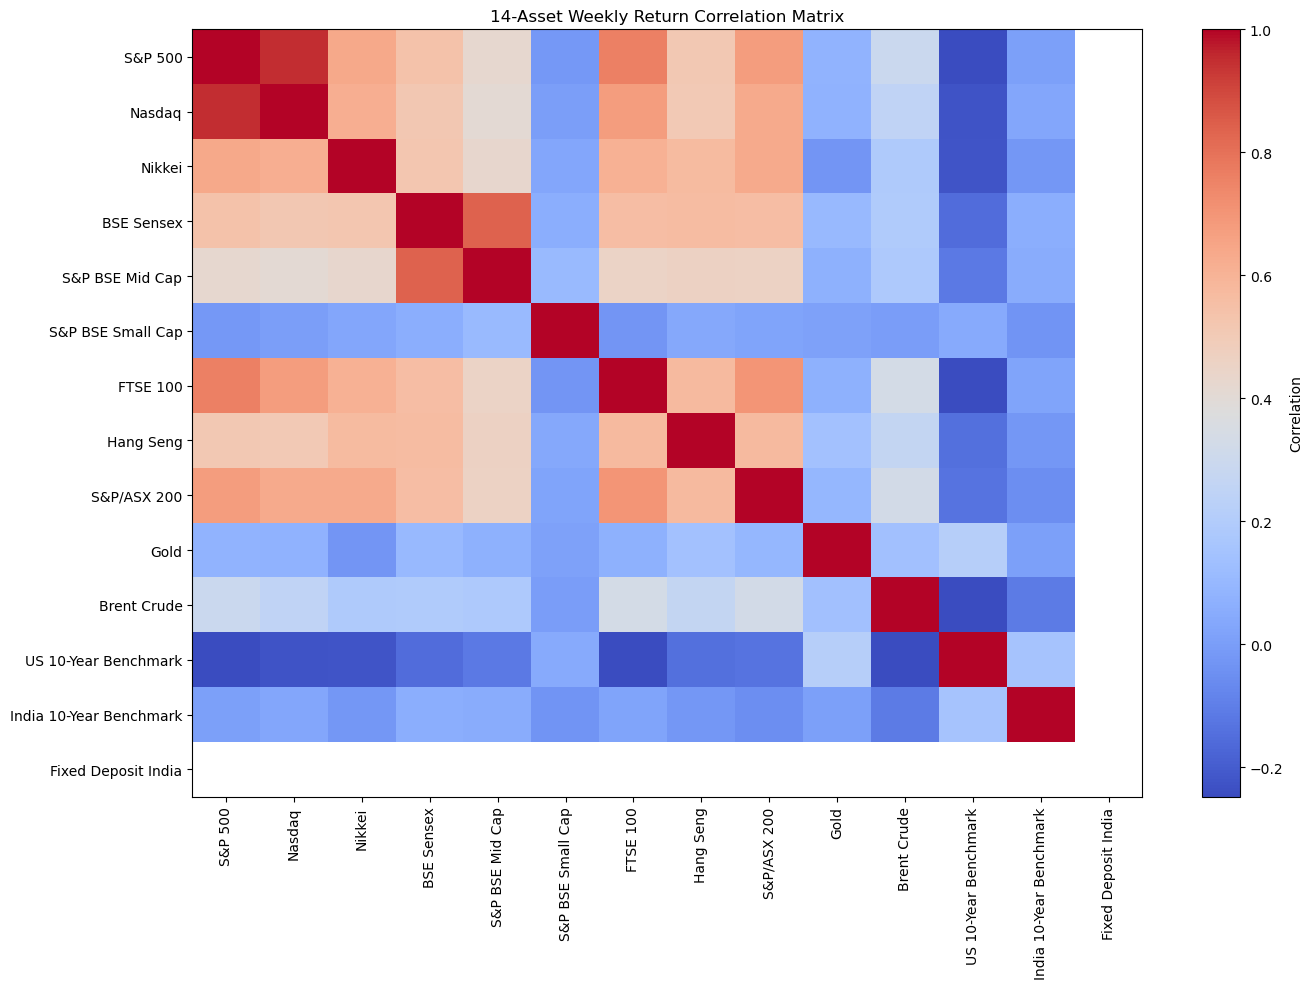

In [32]:
# Correlation heatmap

plt.figure(figsize=(14, 10))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    aspect="auto"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("14-Asset Weekly Return Correlation Matrix")

plt.tight_layout()
plt.show()

In [33]:
# ==========================================
# COVARIANCE MATRIX
# ==========================================

covariance_matrix = master_returns_clean.cov()

print("Covariance Matrix:")
print(covariance_matrix.round(6))

Covariance Matrix:
                          S&P 500    Nasdaq    Nikkei  BSE Sensex  \
S&P 500                  0.000627  0.000673  0.000487    0.000366   
Nasdaq                   0.000673  0.000802  0.000535    0.000395   
Nikkei                   0.000487  0.000535  0.000929    0.000427   
BSE Sensex               0.000366  0.000395  0.000427    0.000730   
S&P BSE Mid Cap          0.000324  0.000354  0.000398    0.000693   
S&P BSE Small Cap       -0.000014  0.000004  0.000037    0.000060   
FTSE 100                 0.000452  0.000454  0.000441    0.000359   
Hang Seng                0.000394  0.000439  0.000533    0.000468   
S&P/ASX 200              0.000370  0.000391  0.000422    0.000330   
Gold                     0.000049  0.000052 -0.000018    0.000069   
Brent Crude              0.000383  0.000366  0.000300    0.000270   
US 10-Year Benchmark    -0.000065 -0.000066 -0.000071   -0.000043   
India 10-Year Benchmark  0.000001  0.000008 -0.000006    0.000014   
Fixed Deposit I

In [34]:
# ==========================================
# PORTFOLIO CONSTRAINTS
# ==========================================

asset_constraints = {
    # Equity indices
    "S&P 500": (0.05, 0.25),
    "Nasdaq": (0.05, 0.25),
    "Nikkei": (0.05, 0.25),
    "BSE Sensex": (0.05, 0.25),
    "S&P BSE Mid Cap": (0.05, 0.25),
    "S&P BSE Small Cap": (0.05, 0.25),
    "FTSE 100": (0.05, 0.25),
    "Hang Seng": (0.05, 0.25),
    "S&P/ASX 200": (0.05, 0.25),

    # Commodities
    "Gold": (0.05, 0.25),
    "Brent Crude": (0.05, 0.25),

    # Bonds
    "US 10-Year Benchmark": (0.05, 0.25),
    "India 10-Year Benchmark": (0.05, 0.25),

    # Cash
    "Fixed Deposit India": (0.01, 0.15)
}

print("Portfolio constraints set successfully.")

Portfolio constraints set successfully.


In [35]:
# ==========================================
# MONTE CARLO PORTFOLIO SIMULATION
# ==========================================

np.random.seed(42)

assets = master_returns_clean.columns.tolist()
n_assets = len(assets)

# Annualized arithmetic mean returns
annual_mean_returns = master_returns_clean.mean() * 52

# Annualized covariance matrix
annual_covariance = master_returns_clean.cov() * 52

# Risk-free rate
rf = RISK_FREE_RATE

# Number of portfolios
n_portfolios = 10000

portfolio_results = []
portfolio_weights = []

for _ in range(n_portfolios):

    # Randomly select between 4 and 8 assets
    n_selected = np.random.randint(MIN_ASSETS, MAX_ASSETS + 1)

    selected_assets = np.random.choice(
        assets,
        size=n_selected,
        replace=False
    )

    # Minimum weights
    min_weights = np.array([
        0.01 if asset == "Fixed Deposit India" else 0.05
        for asset in selected_assets
    ])

    # Maximum weights
    max_weights = np.array([
        0.15 if asset == "Fixed Deposit India" else 0.25
        for asset in selected_assets
    ])

    # Generate feasible weights
    for attempt in range(1000):

        remaining = 1 - min_weights.sum()

        random_weights = np.random.dirichlet(
            np.ones(n_selected)
        )

        weights = min_weights + remaining * random_weights

        if np.all(weights <= max_weights):
            break

    else:
        continue

    # Create full 14-asset weight vector
    full_weights = np.zeros(n_assets)

    for asset, weight in zip(selected_assets, weights):
        full_weights[assets.index(asset)] = weight

    # Portfolio return
    portfolio_return = np.dot(
        full_weights,
        annual_mean_returns.values
    )

    # Portfolio volatility
    portfolio_volatility = np.sqrt(
        np.dot(
            full_weights,
            np.dot(
                annual_covariance.values,
                full_weights
            )
        )
    )

    # Sharpe ratio
    sharpe_ratio = (
        portfolio_return - rf
    ) / portfolio_volatility

    portfolio_results.append([
        portfolio_return,
        portfolio_volatility,
        sharpe_ratio,
        n_selected
    ])

    portfolio_weights.append(full_weights)


# Convert results to DataFrame

portfolio_results = pd.DataFrame(
    portfolio_results,
    columns=[
        "Return",
        "Volatility",
        "Sharpe Ratio",
        "Number of Assets"
    ]
)

portfolio_weights = pd.DataFrame(
    portfolio_weights,
    columns=assets
)

print("Monte Carlo simulation completed.")
print("Portfolios generated:", len(portfolio_results))

print("\nBest Sharpe Ratio:")
print(portfolio_results["Sharpe Ratio"].max())

Monte Carlo simulation completed.
Portfolios generated: 7766

Best Sharpe Ratio:
0.5952706073630851


#Q1 optimal portfolio based on maximum Sharpe ratio

In [36]:
# ==========================================
# MAXIMUM SHARPE PORTFOLIO
# ==========================================

# Find portfolio with highest Sharpe ratio
max_sharpe_index = portfolio_results["Sharpe Ratio"].idxmax()

# Get its performance
max_sharpe_portfolio = portfolio_results.loc[max_sharpe_index]

# Get its weights
max_sharpe_weights = portfolio_weights.loc[max_sharpe_index]

print("MAXIMUM SHARPE PORTFOLIO")
print("========================")

print("\nAnnual Return:",
      round(max_sharpe_portfolio["Return"] * 100, 2), "%")

print("Annual Volatility:",
      round(max_sharpe_portfolio["Volatility"] * 100, 2), "%")

print("Sharpe Ratio:",
      round(max_sharpe_portfolio["Sharpe Ratio"], 4))

print("Number of Assets:",
      int(max_sharpe_portfolio["Number of Assets"]))

print("\nPortfolio Weights:")

for asset, weight in max_sharpe_weights.items():
    if weight > 0:
        print(asset, ":", round(weight * 100, 2), "%")

MAXIMUM SHARPE PORTFOLIO

Annual Return: 12.54 %
Annual Volatility: 10.99 %
Sharpe Ratio: 0.5953
Number of Assets: 5

Portfolio Weights:
Nasdaq : 21.01 %
S&P BSE Mid Cap : 24.87 %
S&P BSE Small Cap : 20.99 %
Gold : 19.39 %
Fixed Deposit India : 13.74 %


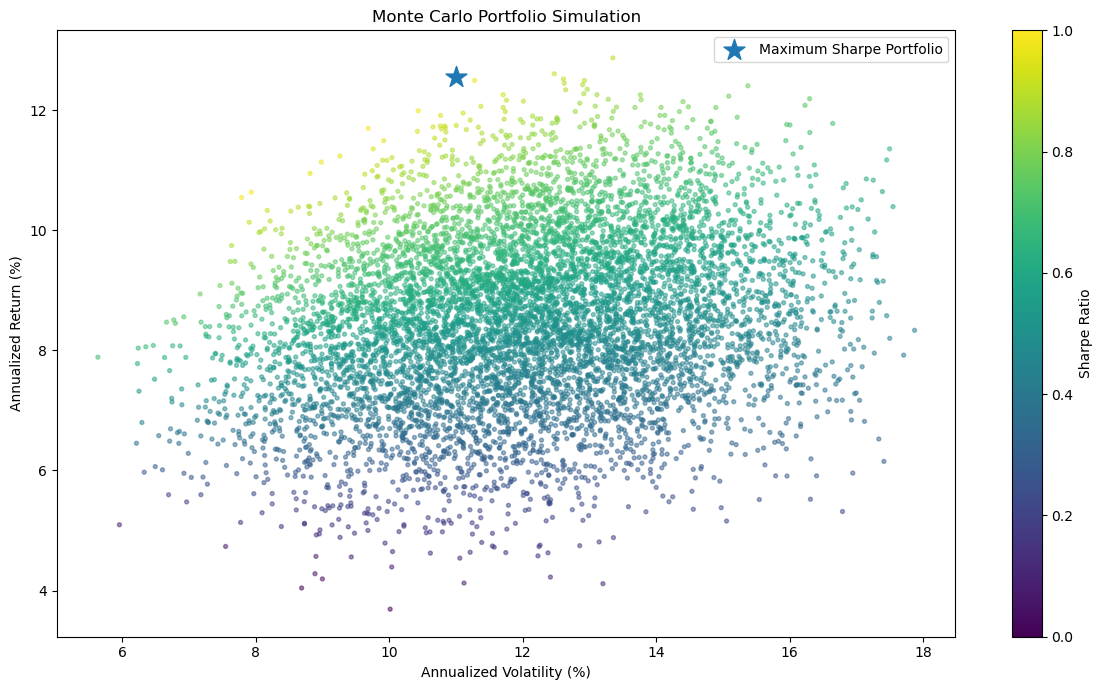

In [37]:
# ==========================================
# MONTE CARLO SIMULATION PLOT
# ==========================================

plt.figure(figsize=(12, 7))

plt.scatter(
    portfolio_results["Volatility"] * 100,
    portfolio_results["Return"] * 100,
    c=portfolio_results["Sharpe Ratio"],
    cmap="viridis",
    s=8,
    alpha=0.5
)

# Mark Maximum Sharpe Portfolio
plt.scatter(
    max_sharpe_portfolio["Volatility"] * 100,
    max_sharpe_portfolio["Return"] * 100,
    marker="*",
    s=250,
    label="Maximum Sharpe Portfolio"
)

plt.xlabel("Annualized Volatility (%)")
plt.ylabel("Annualized Return (%)")
plt.title("Monte Carlo Portfolio Simulation")
plt.colorbar(label="Sharpe Ratio")
plt.legend()

plt.tight_layout()
plt.show()

In [38]:
# ==========================================
# VERIFY MAXIMUM SHARPE PORTFOLIO
# ==========================================

print("MAXIMUM SHARPE PORTFOLIO — WEIGHT CHECK")
print("=" * 50)

for asset, weight in max_sharpe_weights.items():
    
    if weight > 0:
        
        minimum, maximum = asset_constraints[asset]
        
        print(
            f"{asset}: "
            f"{weight*100:.2f}% "
            f"(Allowed: {minimum*100:.0f}%–{maximum*100:.0f}%)"
        )

print("\nTotal Weight:",
      round(max_sharpe_weights.sum() * 100, 2), "%")

print(
    "Number of Assets:",
    int((max_sharpe_weights > 0).sum())
)

MAXIMUM SHARPE PORTFOLIO — WEIGHT CHECK
Nasdaq: 21.01% (Allowed: 5%–25%)
S&P BSE Mid Cap: 24.87% (Allowed: 5%–25%)
S&P BSE Small Cap: 20.99% (Allowed: 5%–25%)
Gold: 19.39% (Allowed: 5%–25%)
Fixed Deposit India: 13.74% (Allowed: 1%–15%)

Total Weight: 100.0 %
Number of Assets: 5


In [39]:
# ==========================================
# Q1 OPTIMAL PORTFOLIO
# ==========================================

q1_portfolio = max_sharpe_weights[
    max_sharpe_weights > 0
].sort_values(ascending=False)

print("Q1 OPTIMAL PORTFOLIO")
print("=" * 40)

for asset, weight in q1_portfolio.items():
    print(f"{asset}: {weight*100:.2f}%")

print("\nTotal:", round(q1_portfolio.sum()*100, 2), "%")

Q1 OPTIMAL PORTFOLIO
S&P BSE Mid Cap: 24.87%
Nasdaq: 21.01%
S&P BSE Small Cap: 20.99%
Gold: 19.39%
Fixed Deposit India: 13.74%

Total: 100.0 %


#Q2 2008 Global Financial Crisis backtesting

In [40]:
# ==========================================
# Q2.1 — GLOBAL FINANCIAL CRISIS (2008)
# ==========================================

gfc_2008 = master_returns_clean.loc[
    "2008-01-01":"2008-12-31"
].copy()

print("GFC 2008 BACKTEST PERIOD")
print("=========================")

print("Start:", gfc_2008.index.min())
print("End:", gfc_2008.index.max())

print("Number of weekly observations:", len(gfc_2008))

GFC 2008 BACKTEST PERIOD
Start: 2008-01-04 00:00:00
End: 2008-12-26 00:00:00
Number of weekly observations: 52


In [41]:
# ==========================================
# Q1 PORTFOLIO PERFORMANCE DURING 2008
# ==========================================

# Select only the Q1 portfolio assets
gfc_portfolio_returns = gfc_2008[
    q1_portfolio.index
].copy()

# Portfolio weekly returns
gfc_portfolio_returns["Q1 Portfolio"] = (
    gfc_portfolio_returns
    .mul(q1_portfolio)
    .sum(axis=1)
)

# Cumulative portfolio value
gfc_portfolio_value = (
    1 + gfc_portfolio_returns["Q1 Portfolio"]
).cumprod()

# Total return during 2008
gfc_total_return = (
    gfc_portfolio_value.iloc[-1] - 1
)

# Annualized volatility based on 2008 weekly observations
gfc_volatility = (
    gfc_portfolio_returns["Q1 Portfolio"].std()
    * np.sqrt(52)
)

print("Q1 PORTFOLIO — 2008 GFC")
print("=========================")

print("Total Return:",
      round(gfc_total_return * 100, 2), "%")

print("Annualized Volatility:",
      round(gfc_volatility * 100, 2), "%")

print("\nAsset-level 2008 returns:")

asset_2008_returns = (
    (1 + gfc_portfolio_returns[q1_portfolio.index])
    .prod() - 1
)

print(
    (asset_2008_returns * 100)
    .round(2)
)

Q1 PORTFOLIO — 2008 GFC
Total Return: -41.43 %
Annualized Volatility: 20.08 %

Asset-level 2008 returns:
S&P BSE Mid Cap       -67.06
Nasdaq                -42.78
S&P BSE Small Cap     -63.04
Gold                    3.67
Fixed Deposit India     6.48
dtype: float64


In [42]:
# ==========================================
# Q2.1 — GLOBAL FINANCIAL CRISIS (2008)
# ==========================================

gfc_2008 = master_returns_clean.loc[
    "2008-01-01":"2008-12-31"
].copy()

print("GFC 2008 BACKTEST PERIOD")
print("=========================")
print("Start:", gfc_2008.index.min())
print("End:", gfc_2008.index.max())
print("Weekly observations:", len(gfc_2008))

GFC 2008 BACKTEST PERIOD
Start: 2008-01-04 00:00:00
End: 2008-12-26 00:00:00
Weekly observations: 52


In [43]:
# ==========================================
# Q1 PORTFOLIO PERFORMANCE — 2008 GFC
# ==========================================

# Get returns of the assets in our Q1 portfolio
gfc_asset_returns = gfc_2008[q1_portfolio.index].copy()

# Calculate portfolio return each week
gfc_weekly_portfolio_return = (
    gfc_asset_returns * q1_portfolio
).sum(axis=1)

# Cumulative portfolio growth
gfc_growth = (1 + gfc_weekly_portfolio_return).cumprod()

# Total return over 2008
gfc_total_return = gfc_growth.iloc[-1] - 1

# Annualized volatility
gfc_volatility = (
    gfc_weekly_portfolio_return.std() * np.sqrt(52)
)

print("Q1 PORTFOLIO — 2008 GFC")
print("========================")
print("Total Return:",
      round(gfc_total_return * 100, 2), "%")

print("Annualized Volatility:",
      round(gfc_volatility * 100, 2), "%")

print("\nAsset-level 2008 Returns:")
print(
    ((1 + gfc_asset_returns).prod() - 1) * 100
)

Q1 PORTFOLIO — 2008 GFC
Total Return: -41.43 %
Annualized Volatility: 20.08 %

Asset-level 2008 Returns:
S&P BSE Mid Cap       -67.064684
Nasdaq                -42.783216
S&P BSE Small Cap     -63.036388
Gold                    3.668419
Fixed Deposit India     6.481627
dtype: float64


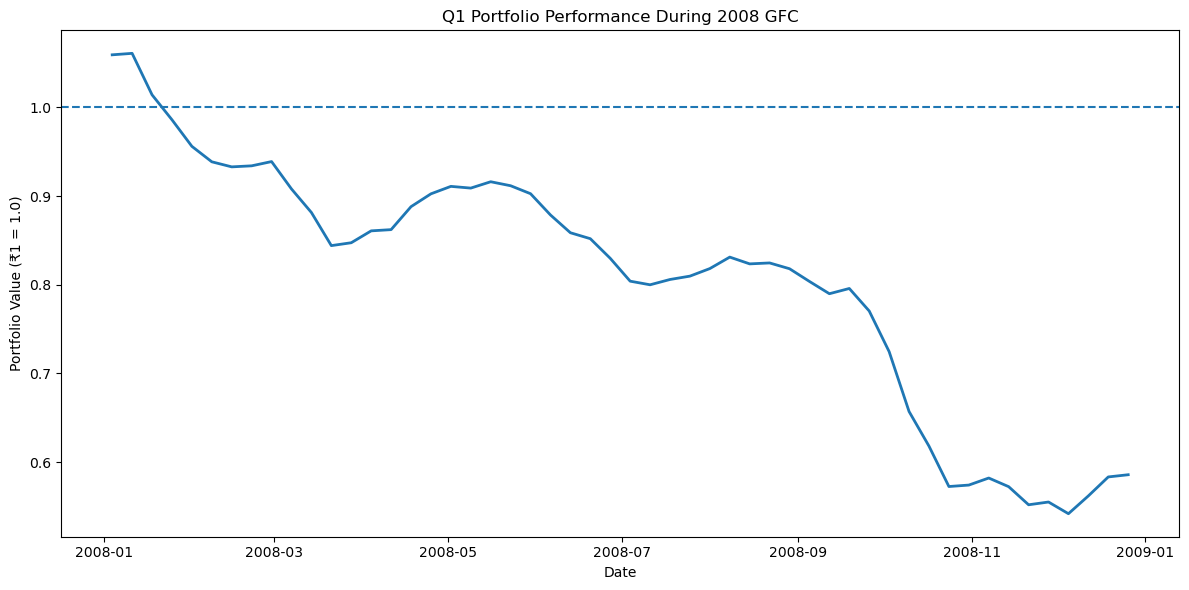

In [44]:
# ==========================================
# Q1 PORTFOLIO VALUE DURING 2008 GFC
# ==========================================

plt.figure(figsize=(12, 6))

plt.plot(
    gfc_growth.index,
    gfc_growth,
    linewidth=2
)

plt.axhline(
    1,
    linestyle="--"
)

plt.title("Q1 Portfolio Performance During 2008 GFC")
plt.xlabel("Date")
plt.ylabel("Portfolio Value (₹1 = 1.0)")

plt.tight_layout()
plt.show()

# THE OPTIMAL PERFORMING PORTFOLIO DURING GFC2 2008

In [45]:
# ==========================================
# 2008 GFC STRESS PORTFOLIO OPTIMIZATION
# ==========================================

np.random.seed(42)

gfc_mean_returns = gfc_2008.mean() * 52
gfc_covariance = gfc_2008.cov() * 52

gfc_results = []
gfc_weights = []

for _ in range(10000):

    # Select 4 to 8 assets
    n_selected = np.random.randint(4, 9)

    selected_assets = np.random.choice(
        assets,
        size=n_selected,
        replace=False
    )

    # Minimum and maximum weights
    min_weights = np.array([
        0.01 if asset == "Fixed Deposit India" else 0.05
        for asset in selected_assets
    ])

    max_weights = np.array([
        0.15 if asset == "Fixed Deposit India" else 0.25
        for asset in selected_assets
    ])

    # Generate feasible weights
    for attempt in range(1000):

        remaining = 1 - min_weights.sum()

        random_weights = np.random.dirichlet(
            np.ones(n_selected)
        )

        weights = min_weights + remaining * random_weights

        if np.all(weights <= max_weights):
            break
    else:
        continue

    # Full 14-asset vector
    full_weights = np.zeros(len(assets))

    for asset, weight in zip(selected_assets, weights):
        full_weights[assets.index(asset)] = weight

    # Portfolio statistics
    portfolio_return = np.dot(
        full_weights,
        gfc_mean_returns.values
    )

    portfolio_volatility = np.sqrt(
        np.dot(
            full_weights,
            np.dot(
                gfc_covariance.values,
                full_weights
            )
        )
    )

    sharpe = (
        portfolio_return - RISK_FREE_RATE
    ) / portfolio_volatility

    gfc_results.append([
        portfolio_return,
        portfolio_volatility,
        sharpe,
        n_selected
    ])

    gfc_weights.append(full_weights)


gfc_results = pd.DataFrame(
    gfc_results,
    columns=[
        "Return",
        "Volatility",
        "Sharpe Ratio",
        "Number of Assets"
    ]
)

gfc_weights = pd.DataFrame(
    gfc_weights,
    columns=assets
)

print("2008 GFC stress simulation completed.")
print("Valid portfolios:", len(gfc_results))
print("Best GFC Sharpe:",
      round(gfc_results["Sharpe Ratio"].max(), 4))

2008 GFC stress simulation completed.
Valid portfolios: 7766
Best GFC Sharpe: -0.4249


In [46]:
# ==========================================
# BEST 2008 GFC STRESS PORTFOLIO
# ==========================================

gfc_best_index = gfc_results["Sharpe Ratio"].idxmax()

gfc_best = gfc_results.loc[gfc_best_index]
gfc_best_weights = gfc_weights.loc[gfc_best_index]

print("BEST 2008 GFC STRESS PORTFOLIO")
print("=" * 45)

print("\nAnnualized Return:",
      round(gfc_best["Return"] * 100, 2), "%")

print("Annualized Volatility:",
      round(gfc_best["Volatility"] * 100, 2), "%")

print("Sharpe Ratio:",
      round(gfc_best["Sharpe Ratio"], 4))

print("Number of Assets:",
      int(gfc_best["Number of Assets"]))

print("\nPortfolio Weights:")

for asset, weight in gfc_best_weights.items():
    if weight > 0:
        print(f"{asset}: {weight * 100:.2f}%")

BEST 2008 GFC STRESS PORTFOLIO

Annualized Return: 1.18 %
Annualized Volatility: 11.34 %
Sharpe Ratio: -0.4249
Number of Assets: 6

Portfolio Weights:
S&P 500: 8.84%
FTSE 100: 18.05%
Gold: 22.62%
US 10-Year Benchmark: 22.29%
India 10-Year Benchmark: 20.95%
Fixed Deposit India: 7.23%


In [47]:
# ==========================================
# Q1 vs 2008 GFC STRESS PORTFOLIO
# ==========================================

comparison_2008 = pd.DataFrame({
    "Q1 Optimal Portfolio": [
        max_sharpe_portfolio["Return"] * 100,
        max_sharpe_portfolio["Volatility"] * 100,
        max_sharpe_portfolio["Sharpe Ratio"]
    ],
    "2008 GFC Stress Portfolio": [
        gfc_best["Return"] * 100,
        gfc_best["Volatility"] * 100,
        gfc_best["Sharpe Ratio"]
    ]
}, index=[
    "Annual Return (%)",
    "Annual Volatility (%)",
    "Sharpe Ratio"
])

print("Q1 vs 2008 GFC STRESS PORTFOLIO")
print("=" * 45)
print(comparison_2008.round(2))

Q1 vs 2008 GFC STRESS PORTFOLIO
                       Q1 Optimal Portfolio  2008 GFC Stress Portfolio
Annual Return (%)                     12.54                       1.18
Annual Volatility (%)                 10.99                      11.34
Sharpe Ratio                           0.60                      -0.42


In [48]:
# ==========================================
# POST-GFC PERFORMANCE: 2009–2011
# ==========================================

post_gfc = master_returns_clean.loc[
    "2009-01-01":"2011-12-31"
].copy()

# Returns of the new GFC stress portfolio
post_gfc_asset_returns = post_gfc[
    gfc_best_weights.index[gfc_best_weights > 0]
].copy()

# Portfolio weekly returns
post_gfc_portfolio_returns = (
    post_gfc_asset_returns * gfc_best_weights[
        gfc_best_weights > 0
    ]
).sum(axis=1)

# Cumulative growth
post_gfc_growth = (
    1 + post_gfc_portfolio_returns
).cumprod()

# Total return
post_gfc_total_return = (
    post_gfc_growth.iloc[-1] - 1
)

# Annualized volatility
post_gfc_volatility = (
    post_gfc_portfolio_returns.std()
    * np.sqrt(52)
)

print("POST-GFC PERFORMANCE — 2009–2011")
print("=" * 45)

print("Total Return:",
      round(post_gfc_total_return * 100, 2), "%")

print("Annualized Volatility:",
      round(post_gfc_volatility * 100, 2), "%")

print("Weekly Observations:",
      len(post_gfc_portfolio_returns))

POST-GFC PERFORMANCE — 2009–2011
Total Return: 32.43 %
Annualized Volatility: 7.32 %
Weekly Observations: 157


# 2020 COVID STRESS SCENARIO

In [49]:
covid_2020 = master_returns_clean.loc["2020-01-01":"2020-12-31"].copy()

print("COVID-19 PERIOD — 2020")
print("Observations:", len(covid_2020))
print("Start:", covid_2020.index.min())
print("End:", covid_2020.index.max())

COVID-19 PERIOD — 2020
Observations: 52
Start: 2020-01-03 00:00:00
End: 2020-12-25 00:00:00


In [50]:
covid_asset_returns = covid_2020[q1_portfolio.index].copy()

covid_weekly_portfolio_return = (
    covid_asset_returns * q1_portfolio
).sum(axis=1)

covid_growth = (1 + covid_weekly_portfolio_return).cumprod()

covid_total_return = covid_growth.iloc[-1] - 1
covid_volatility = covid_weekly_portfolio_return.std() * np.sqrt(52)

print("Q1 PORTFOLIO — COVID-19 2020")
print("Total Return:", round(covid_total_return * 100, 2), "%")
print("Annualized Volatility:", round(covid_volatility * 100, 2), "%")

Q1 PORTFOLIO — COVID-19 2020
Total Return: 28.78 %
Annualized Volatility: 16.54 %


In [51]:
# COVID 2020 stress portfolio optimization

covid_mean_returns = covid_2020.mean() * 52
covid_covariance = covid_2020.cov() * 52

covid_results = []
covid_weights = []

for _ in range(N_PORTFOLIOS):

    n_assets = np.random.randint(MIN_ASSETS, MAX_ASSETS + 1)
    selected_assets = np.random.choice(
        assets,
        size=n_assets,
        replace=False
    )

    weights = np.zeros(len(assets))

    raw_weights = np.random.dirichlet(np.ones(n_assets))

    valid = True

    for asset, weight in zip(selected_assets, raw_weights):
        min_w, max_w = asset_constraints[asset]

        if weight < min_w or weight > max_w:
            valid = False
            break

        weights[assets.index(asset)] = weight

    if not valid:
        continue

    if not np.isclose(weights.sum(), 1):
        continue

    portfolio_return = np.dot(weights, covid_mean_returns)
    portfolio_volatility = np.sqrt(
        np.dot(weights.T, np.dot(covid_covariance, weights))
    )

    sharpe_ratio = (
        portfolio_return - RISK_FREE_RATE
    ) / portfolio_volatility

    covid_results.append([
        portfolio_return,
        portfolio_volatility,
        sharpe_ratio
    ])

    covid_weights.append(weights)

covid_results = pd.DataFrame(
    covid_results,
    columns=["Return", "Volatility", "Sharpe Ratio"]
)

covid_weights = pd.DataFrame(
    covid_weights,
    columns=assets
)

print("Valid COVID portfolios generated:", len(covid_results))

Valid COVID portfolios generated: 85


In [52]:
covid_best_index = covid_results["Sharpe Ratio"].idxmax()

covid_best = covid_results.loc[covid_best_index]
covid_best_weights = covid_weights.loc[covid_best_index]

print("COVID STRESS PORTFOLIO")
print("\nPerformance:")
print("Annual Return:", round(covid_best["Return"] * 100, 2), "%")
print("Annual Volatility:", round(covid_best["Volatility"] * 100, 2), "%")
print("Sharpe Ratio:", round(covid_best["Sharpe Ratio"], 3))

print("\nAsset Weights:")
print(
    covid_best_weights[covid_best_weights > 0]
    .sort_values(ascending=False)
    .mul(100)
    .round(2)
)

COVID STRESS PORTFOLIO

Performance:
Annual Return: 23.86 %
Annual Volatility: 19.86 %
Sharpe Ratio: 0.899

Asset Weights:
S&P BSE Small Cap          24.41
Nasdaq                     17.62
S&P BSE Mid Cap            12.97
S&P 500                    12.58
Nikkei                     11.32
FTSE 100                    8.03
Gold                        8.00
India 10-Year Benchmark     5.07
Name: 41, dtype: float64


In [53]:
covid_comparison = pd.DataFrame({
    "Q1 Optimal Portfolio": [
        max_sharpe_portfolio["Return"] * 100,
        max_sharpe_portfolio["Volatility"] * 100,
        max_sharpe_portfolio["Sharpe Ratio"]
    ],
    "COVID Stress Portfolio": [
        covid_best["Return"] * 100,
        covid_best["Volatility"] * 100,
        covid_best["Sharpe Ratio"]
    ]
}, index=[
    "Annual Return (%)",
    "Annual Volatility (%)",
    "Sharpe Ratio"
])

covid_comparison.round(2)

,Q1 Optimal Portfolio,COVID Stress Portfolio
Annual Return (%),12.54,23.86
Annual Volatility (%),10.99,19.86
Sharpe Ratio,0.60,0.90


In [54]:
post_covid = master_returns_clean.loc["2021-01-01":"2022-12-31"].copy()

post_covid_asset_returns = post_covid[
    covid_best_weights.index[covid_best_weights > 0]
].copy()

post_covid_portfolio_returns = (
    post_covid_asset_returns
    * covid_best_weights[covid_best_weights > 0]
).sum(axis=1)

post_covid_growth = (
    1 + post_covid_portfolio_returns
).cumprod()

post_covid_total_return = post_covid_growth.iloc[-1] - 1
post_covid_volatility = (
    post_covid_portfolio_returns.std() * np.sqrt(52)
)

print("POST-COVID PERFORMANCE — 2021–2022")
print("Total Return:", round(post_covid_total_return * 100, 2), "%")
print(
    "Annualized Volatility:",
    round(post_covid_volatility * 100, 2),
    "%"
)

POST-COVID PERFORMANCE — 2021–2022
Total Return: 16.78 %
Annualized Volatility: 11.35 %


# 2022 Russia–Ukraine War scenario

In [55]:
ukraine_2022 = master_returns_clean.loc[
    "2022-01-01":"2022-12-31"
].copy()

print("RUSSIA–UKRAINE WAR — 2022")
print("Observations:", len(ukraine_2022))
print("Start:", ukraine_2022.index.min())
print("End:", ukraine_2022.index.max())

RUSSIA–UKRAINE WAR — 2022
Observations: 52
Start: 2022-01-07 00:00:00
End: 2022-12-30 00:00:00


In [56]:
ukraine_asset_returns = ukraine_2022[q1_portfolio.index].copy()

ukraine_weekly_portfolio_return = (
    ukraine_asset_returns * q1_portfolio
).sum(axis=1)

ukraine_growth = (
    1 + ukraine_weekly_portfolio_return
).cumprod()

ukraine_total_return = ukraine_growth.iloc[-1] - 1

ukraine_volatility = (
    ukraine_weekly_portfolio_return.std() * np.sqrt(52)
)

print("Q1 PORTFOLIO — RUSSIA–UKRAINE WAR 2022")
print("Total Return:", round(ukraine_total_return * 100, 2), "%")
print(
    "Annualized Volatility:",
    round(ukraine_volatility * 100, 2),
    "%"
)

Q1 PORTFOLIO — RUSSIA–UKRAINE WAR 2022
Total Return: -6.09 %
Annualized Volatility: 10.87 %


In [57]:
ukraine_mean_returns = ukraine_2022.mean() * 52
ukraine_covariance = ukraine_2022.cov() * 52

ukraine_results = []
ukraine_weights = []

for _ in range(N_PORTFOLIOS):

    n_assets = np.random.randint(MIN_ASSETS, MAX_ASSETS + 1)

    selected_assets = np.random.choice(
        assets,
        size=n_assets,
        replace=False
    )

    weights = np.zeros(len(assets))

    raw_weights = np.random.dirichlet(np.ones(n_assets))

    valid = True

    for asset, weight in zip(selected_assets, raw_weights):

        min_w, max_w = asset_constraints[asset]

        if weight < min_w or weight > max_w:
            valid = False
            break

        weights[assets.index(asset)] = weight

    if not valid:
        continue

    if not np.isclose(weights.sum(), 1):
        continue

    portfolio_return = np.dot(
        weights,
        ukraine_mean_returns
    )

    portfolio_volatility = np.sqrt(
        np.dot(
            weights.T,
            np.dot(ukraine_covariance, weights)
        )
    )

    sharpe_ratio = (
        portfolio_return - RISK_FREE_RATE
    ) / portfolio_volatility

    ukraine_results.append([
        portfolio_return,
        portfolio_volatility,
        sharpe_ratio
    ])

    ukraine_weights.append(weights)

ukraine_results = pd.DataFrame(
    ukraine_results,
    columns=["Return", "Volatility", "Sharpe Ratio"]
)

ukraine_weights = pd.DataFrame(
    ukraine_weights,
    columns=assets
)

print(
    "Valid 2022 stress portfolios generated:",
    len(ukraine_results)
)

Valid 2022 stress portfolios generated: 107


In [58]:
ukraine_best_index = ukraine_results["Sharpe Ratio"].idxmax()

ukraine_best = ukraine_results.loc[ukraine_best_index]
ukraine_best_weights = ukraine_weights.loc[ukraine_best_index]

print("2022 RUSSIA–UKRAINE STRESS PORTFOLIO")

print("\nPerformance:")
print("Annual Return:", round(ukraine_best["Return"] * 100, 2), "%")
print("Annual Volatility:", round(ukraine_best["Volatility"] * 100, 2), "%")
print("Sharpe Ratio:", round(ukraine_best["Sharpe Ratio"], 3))

print("\nAsset Weights:")
print(
    ukraine_best_weights[ukraine_best_weights > 0]
    .sort_values(ascending=False)
    .mul(100)
    .round(2)
)

2022 RUSSIA–UKRAINE STRESS PORTFOLIO

Performance:
Annual Return: 4.37 %
Annual Volatility: 14.93 %
Sharpe Ratio: -0.109

Asset Weights:
Brent Crude            24.82
Nikkei                 15.82
S&P BSE Mid Cap        14.70
Gold                   12.96
BSE Sensex             12.69
FTSE 100                8.60
Hang Seng               8.08
Fixed Deposit India     2.34
Name: 105, dtype: float64


In [59]:
ukraine_comparison = pd.DataFrame({
    "Q1 Optimal Portfolio": [
        max_sharpe_portfolio["Return"] * 100,
        max_sharpe_portfolio["Volatility"] * 100,
        max_sharpe_portfolio["Sharpe Ratio"]
    ],
    "2022 Stress Portfolio": [
        ukraine_best["Return"] * 100,
        ukraine_best["Volatility"] * 100,
        ukraine_best["Sharpe Ratio"]
    ]
}, index=[
    "Annual Return (%)",
    "Annual Volatility (%)",
    "Sharpe Ratio"
])

ukraine_comparison.round(2)

,Q1 Optimal Portfolio,2022 Stress Portfolio
Annual Return (%),12.54,4.37
Annual Volatility (%),10.99,14.93
Sharpe Ratio,0.60,-0.11


In [60]:
post_ukraine = master_returns_clean.loc[
    "2023-01-01":"2024-12-31"
].copy()

post_ukraine_asset_returns = post_ukraine[
    ukraine_best_weights.index[
        ukraine_best_weights > 0
    ]
].copy()

post_ukraine_portfolio_returns = (
    post_ukraine_asset_returns
    * ukraine_best_weights[
        ukraine_best_weights > 0
    ]
).sum(axis=1)

post_ukraine_growth = (
    1 + post_ukraine_portfolio_returns
).cumprod()

post_ukraine_total_return = (
    post_ukraine_growth.iloc[-1] - 1
)

post_ukraine_volatility = (
    post_ukraine_portfolio_returns.std()
    * np.sqrt(52)
)

print("POST-2022 PERFORMANCE — 2023–2024")
print(
    "Total Return:",
    round(post_ukraine_total_return * 100, 2),
    "%"
)
print(
    "Annualized Volatility:",
    round(post_ukraine_volatility * 100, 2),
    "%"
)

POST-2022 PERFORMANCE — 2023–2024
Total Return: 27.7 %
Annualized Volatility: 11.38 %


In [61]:
stress_portfolio_summary = pd.DataFrame({
    "Q1 Optimal": [
        max_sharpe_portfolio["Return"] * 100,
        max_sharpe_portfolio["Volatility"] * 100,
        max_sharpe_portfolio["Sharpe Ratio"]
    ],
    "2008 GFC": [
        gfc_best["Return"] * 100,
        gfc_best["Volatility"] * 100,
        gfc_best["Sharpe Ratio"]
    ],
    "2020 COVID": [
        covid_best["Return"] * 100,
        covid_best["Volatility"] * 100,
        covid_best["Sharpe Ratio"]
    ],
    "2022 Russia-Ukraine": [
        ukraine_best["Return"] * 100,
        ukraine_best["Volatility"] * 100,
        ukraine_best["Sharpe Ratio"]
    ]
}, index=[
    "Annual Return (%)",
    "Annual Volatility (%)",
    "Sharpe Ratio"
])

stress_portfolio_summary.round(2)

,Q1 Optimal,2008 GFC,2020 COVID,2022 Russia-Ukraine
Annual Return (%),12.54,1.18,23.86,4.37
Annual Volatility (%),10.99,11.34,19.86,14.93
Sharpe Ratio,0.60,-0.42,0.90,-0.11


In [62]:
forward_stress_summary = pd.DataFrame({
    "2008 GFC Stress Portfolio": [
        post_gfc_total_return * 100,
        post_gfc_volatility * 100
    ],
    "2020 COVID Stress Portfolio": [
        post_covid_total_return * 100,
        post_covid_volatility * 100
    ],
    "2022 Ukraine Stress Portfolio": [
        post_ukraine_total_return * 100,
        post_ukraine_volatility * 100
    ]
}, index=[
    "Subsequent Period Return (%)",
    "Annualized Volatility (%)"
])

forward_stress_summary.round(2)

,2008 GFC Stress Portfolio,2020 COVID Stress Portfolio,2022 Ukraine Stress Portfolio
Subsequent Period Return (%),32.43,16.78,27.70
Annualized Volatility (%),7.32,11.35,11.38


In [63]:
crisis_performance = pd.DataFrame({
    "2008 GFC": [
        gfc_total_return * 100,
        gfc_volatility * 100
    ],
    "2020 COVID": [
        covid_total_return * 100,
        covid_volatility * 100
    ],
    "2022 Russia-Ukraine": [
        ukraine_total_return * 100,
        ukraine_volatility * 100
    ]
}, index=[
    "Q1 Portfolio Return (%)",
    "Annualized Volatility (%)"
])

crisis_performance.round(2)

,2008 GFC,2020 COVID,2022 Russia-Ukraine
Q1 Portfolio Return (%),-41.43,28.78,-6.09
Annualized Volatility (%),20.08,16.54,10.87


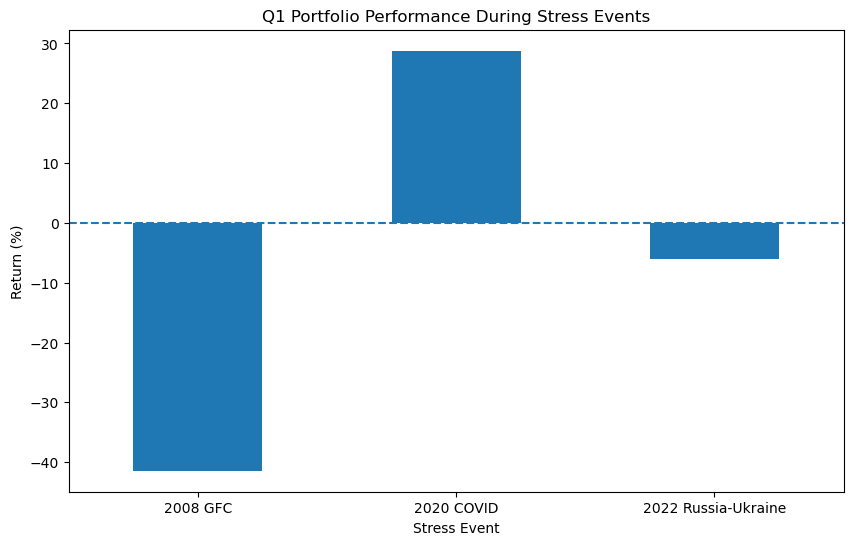

In [64]:
crisis_performance.T["Q1 Portfolio Return (%)"].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.axhline(0, linestyle="--")
plt.title("Q1 Portfolio Performance During Stress Events")
plt.ylabel("Return (%)")
plt.xlabel("Stress Event")
plt.xticks(rotation=0)
plt.show()

In [65]:
stress_weights = pd.DataFrame({
    "2008 GFC": gfc_best_weights,
    "2020 COVID": covid_best_weights,
    "2022 Russia-Ukraine": ukraine_best_weights
})

stress_weights = stress_weights[
    (stress_weights > 0).any(axis=1)
]

stress_weights = stress_weights * 100

stress_weights.round(2)

,2008 GFC,2020 COVID,2022 Russia-Ukraine
S&P 500,8.84,12.58,0.00
Nasdaq,0.00,17.62,0.00
Nikkei,0.00,11.32,15.82
BSE Sensex,0.00,0.00,12.69
S&P BSE Mid Cap,0.00,12.97,14.70
S&P BSE Small Cap,0.00,24.41,0.00
FTSE 100,18.05,8.03,8.60
Hang Seng,0.00,0.00,8.08
Gold,22.62,8.00,12.96
Brent Crude,0.00,0.00,24.82


In [66]:
q2_final_summary = pd.DataFrame({
    "2008 GFC": [
        gfc_total_return * 100,
        post_gfc_total_return * 100
    ],
    "2020 COVID": [
        covid_total_return * 100,
        post_covid_total_return * 100
    ],
    "2022 Russia-Ukraine": [
        ukraine_total_return * 100,
        post_ukraine_total_return * 100
    ]
}, index=[
    "Original Q1 Portfolio — Crisis Return (%)",
    "Stress Portfolio — Subsequent Return (%)"
])

q2_final_summary.round(2)

,2008 GFC,2020 COVID,2022 Russia-Ukraine
Original Q1 Portfolio — Crisis Return (%),-41.43,28.78,-6.09
Stress Portfolio — Subsequent Return (%),32.43,16.78,27.70


In [67]:
def calculate_max_drawdown(returns):
    growth = (1 + returns).cumprod()
    running_peak = growth.cummax()
    drawdown = (growth / running_peak) - 1
    return drawdown.min()

gfc_mdd = calculate_max_drawdown(gfc_weekly_portfolio_return)
covid_mdd = calculate_max_drawdown(covid_weekly_portfolio_return)
ukraine_mdd = calculate_max_drawdown(ukraine_weekly_portfolio_return)

crisis_drawdown = pd.DataFrame({
    "Maximum Drawdown (%)": [
        gfc_mdd * 100,
        covid_mdd * 100,
        ukraine_mdd * 100
    ]
}, index=[
    "2008 GFC",
    "2020 COVID",
    "2022 Russia-Ukraine"
])

crisis_drawdown.round(2)

,Maximum Drawdown (%)
2008 GFC,-48.93
2020 COVID,-21.55
2022 Russia-Ukraine,-12.68


In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import minimize
import warnings

warnings.filterwarnings("ignore")

print("Libraries loaded successfully")

Libraries loaded successfully


In [69]:
stress_weights = pd.DataFrame({
    "2008 GFC": gfc_best_weights,
    "2020 COVID": covid_best_weights,
    "2022 Russia-Ukraine": ukraine_best_weights
})

stress_weights = stress_weights[
    (stress_weights > 0).any(axis=1)
]

stress_weights = stress_weights * 100

stress_allocation = stress_weights.copy()

stress_allocation.round(2)

,2008 GFC,2020 COVID,2022 Russia-Ukraine
S&P 500,8.84,12.58,0.00
Nasdaq,0.00,17.62,0.00
Nikkei,0.00,11.32,15.82
BSE Sensex,0.00,0.00,12.69
S&P BSE Mid Cap,0.00,12.97,14.70
S&P BSE Small Cap,0.00,24.41,0.00
FTSE 100,18.05,8.03,8.60
Hang Seng,0.00,0.00,8.08
Gold,22.62,8.00,12.96
Brent Crude,0.00,0.00,24.82


In [70]:
final_results = pd.DataFrame({
    "Q1 Optimal Portfolio": [
        max_sharpe_portfolio["Return"] * 100,
        max_sharpe_portfolio["Volatility"] * 100,
        max_sharpe_portfolio["Sharpe Ratio"]
    ],
    "2008 GFC Stress Portfolio": [
        gfc_best["Return"] * 100,
        gfc_best["Volatility"] * 100,
        gfc_best["Sharpe Ratio"]
    ],
    "2020 COVID Stress Portfolio": [
        covid_best["Return"] * 100,
        covid_best["Volatility"] * 100,
        covid_best["Sharpe Ratio"]
    ],
    "2022 Russia-Ukraine Stress Portfolio": [
        ukraine_best["Return"] * 100,
        ukraine_best["Volatility"] * 100,
        ukraine_best["Sharpe Ratio"]
    ]
}, index=[
    "Annual Return (%)",
    "Annual Volatility (%)",
    "Sharpe Ratio"
])

final_results.round(2)

,Q1 Optimal Portfolio,2008 GFC Stress Portfolio,2020 COVID Stress Portfolio,2022 Russia-Ukraine Stress Portfolio
Annual Return (%),12.54,1.18,23.86,4.37
Annual Volatility (%),10.99,11.34,19.86,14.93
Sharpe Ratio,0.60,-0.42,0.90,-0.11


In [72]:
import pandas as pd

# -----------------------------
# RECREATE Q1 SUMMARY TABLES
# -----------------------------

q1_final_allocation = pd.DataFrame({
    "Asset": q1_portfolio.index,
    "Weight (%)": (q1_portfolio.values * 100).round(2)
})

q1_final_summary = pd.DataFrame({
    "Metric": [
        "Annual Return",
        "Annual Volatility",
        "Sharpe Ratio",
        "Number of Assets"
    ],
    "Value": [
        max_sharpe_portfolio["Return"],
        max_sharpe_portfolio["Volatility"],
        max_sharpe_portfolio["Sharpe Ratio"],
        (q1_portfolio > 0).sum()
    ]
})

# -----------------------------
# CREATE EXCEL FILE
# -----------------------------

excel_file = "SAPM_Portfolio_Backtesting_Results.xlsx"

with pd.ExcelWriter(excel_file, engine="openpyxl") as writer:

    q1_final_allocation.to_excel(
        writer,
        sheet_name="Q1 Optimal Portfolio",
        index=False
    )

    q1_final_summary.to_excel(
        writer,
        sheet_name="Q1 Performance",
        index=False
    )

    asset_statistics.to_excel(
        writer,
        sheet_name="Asset Statistics"
    )

    correlation_matrix.to_excel(
        writer,
        sheet_name="Correlation Matrix"
    )

    gfc_best_weights[gfc_best_weights > 0].mul(100).round(2).to_frame(
        "Weight (%)"
    ).to_excel(
        writer,
        sheet_name="2008 GFC Portfolio"
    )

    covid_best_weights[covid_best_weights > 0].mul(100).round(2).to_frame(
        "Weight (%)"
    ).to_excel(
        writer,
        sheet_name="2020 COVID Portfolio"
    )

    ukraine_best_weights[ukraine_best_weights > 0].mul(100).round(2).to_frame(
        "Weight (%)"
    ).to_excel(
        writer,
        sheet_name="2022 Ukraine Portfolio"
    )

    final_results.round(2).to_excel(
        writer,
        sheet_name="Stress Comparison"
    )

    crisis_performance.round(2).to_excel(
        writer,
        sheet_name="Crisis Performance"
    )

    forward_stress_summary.round(2).to_excel(
        writer,
        sheet_name="Forward Performance"
    )

    crisis_drawdown.round(2).to_excel(
        writer,
        sheet_name="Maximum Drawdown"
    )

print("EXCEL FILE CREATED SUCCESSFULLY")
print(excel_file)

EXCEL FILE CREATED SUCCESSFULLY
SAPM_Portfolio_Backtesting_Results.xlsx


In [73]:
import openpyxl

wb = openpyxl.load_workbook(excel_file)

print("Sheets created:")
for sheet in wb.sheetnames:
    print("-", sheet)

print("\nTotal sheets:", len(wb.sheetnames))

Sheets created:
- Q1 Optimal Portfolio
- Q1 Performance
- Asset Statistics
- Correlation Matrix
- 2008 GFC Portfolio
- 2020 COVID Portfolio
- 2022 Ukraine Portfolio
- Stress Comparison
- Crisis Performance
- Forward Performance
- Maximum Drawdown

Total sheets: 11


In [74]:
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# Load the workbook
wb = load_workbook(excel_file)

# Professional formatting
header_fill = PatternFill("solid", fgColor="1F4E78")
header_font = Font(color="FFFFFF", bold=True)
title_font = Font(bold=True, size=12)
thin_border = Border(
    bottom=Side(style="thin", color="D9E1F2")
)

for ws in wb.worksheets:

    # Freeze top row
    ws.freeze_panes = "A2"

    # Format header row
    for cell in ws[1]:
        cell.fill = header_fill
        cell.font = header_font
        cell.alignment = Alignment(
            horizontal="center",
            vertical="center"
        )

    # Format all cells
    for row in ws.iter_rows():
        for cell in row:
            cell.alignment = Alignment(
                vertical="center"
            )
            cell.border = thin_border

    # Automatically adjust column widths
    for column in ws.columns:
        max_length = 0
        column_letter = get_column_letter(column[0].column)

        for cell in column:
            if cell.value is not None:
                max_length = max(
                    max_length,
                    len(str(cell.value))
                )

        ws.column_dimensions[column_letter].width = min(
            max_length + 3,
            35
        )

    # Make first column bold where appropriate
    for cell in ws["A"]:
        if cell.row > 1:
            cell.font = Font(bold=True)

    # Row height
    ws.row_dimensions[1].height = 25


# Save the formatted workbook
wb.save(excel_file)

print("EXCEL WORKBOOK FORMATTED SUCCESSFULLY")
print(excel_file)

EXCEL WORKBOOK FORMATTED SUCCESSFULLY
SAPM_Portfolio_Backtesting_Results.xlsx


In [75]:
import os

print(os.path.abspath(excel_file))

C:\Users\Dell\anaconda_projects\a63ee5b9-a7c0-495a-983b-d924e1e2cac3\SAPM_Portfolio_Backtesting_Results.xlsx


In [76]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

excel_file = "SAPM_Portfolio_Backtesting_Results.xlsx"

xls = pd.ExcelFile(excel_file)
print("Available sheets:")
print(xls.sheet_names)

Available sheets:
['Q1 Optimal Portfolio', 'Q1 Performance', 'Asset Statistics', 'Correlation Matrix', '2008 GFC Portfolio', '2020 COVID Portfolio', '2022 Ukraine Portfolio', 'Stress Comparison', 'Crisis Performance', 'Forward Performance', 'Maximum Drawdown']


In [77]:
# Load the key results from your Excel workbook

q1_allocation = pd.read_excel(
    excel_file, sheet_name="Q1 Optimal Portfolio"
)

q1_performance = pd.read_excel(
    excel_file, sheet_name="Q1 Performance"
)

crisis_performance = pd.read_excel(
    excel_file, sheet_name="Crisis Performance"
)

stress_comparison = pd.read_excel(
    excel_file, sheet_name="Stress Comparison"
)

forward_performance = pd.read_excel(
    excel_file, sheet_name="Forward Performance"
)

print("Q1 PORTFOLIO ALLOCATION")
display(q1_allocation)

print("Q1 PERFORMANCE")
display(q1_performance)

print("CRISIS PERFORMANCE")
display(crisis_performance)

print("STRESS PORTFOLIO COMPARISON")
display(stress_comparison)

print("FORWARD PERFORMANCE")
display(forward_performance)

Q1 PORTFOLIO ALLOCATION


,Asset,Weight (%)
0,S&P BSE Mid Cap,24.87
1,Nasdaq,21.01
2,S&P BSE Small Cap,20.99
3,Gold,19.39
4,Fixed Deposit India,13.74


Q1 PERFORMANCE


,Metric,Value
0,Annual Return,0.125437
1,Annual Volatility,0.109928
2,Sharpe Ratio,0.595271
3,Number of Assets,5.000000


CRISIS PERFORMANCE


,Unnamed: 0,2008 GFC,2020 COVID,2022 Russia-Ukraine
0,Q1 Portfolio Return (%),-41.43,28.78,-6.09
1,Annualized Volatility (%),20.08,16.54,10.87


STRESS PORTFOLIO COMPARISON


,Unnamed: 0,Q1 Optimal Portfolio,2008 GFC Stress Portfolio,2020 COVID Stress Portfolio,2022 Russia-Ukraine Stress Portfolio
0,Annual Return (%),12.54,1.18,23.86,4.37
1,Annual Volatility (%),10.99,11.34,19.86,14.93
2,Sharpe Ratio,0.60,-0.42,0.90,-0.11


FORWARD PERFORMANCE


,Unnamed: 0,2008 GFC Stress Portfolio,2020 COVID Stress Portfolio,2022 Ukraine Stress Portfolio
0,Subsequent Period Return (%),32.43,16.78,27.70
1,Annualized Volatility (%),7.32,11.35,11.38


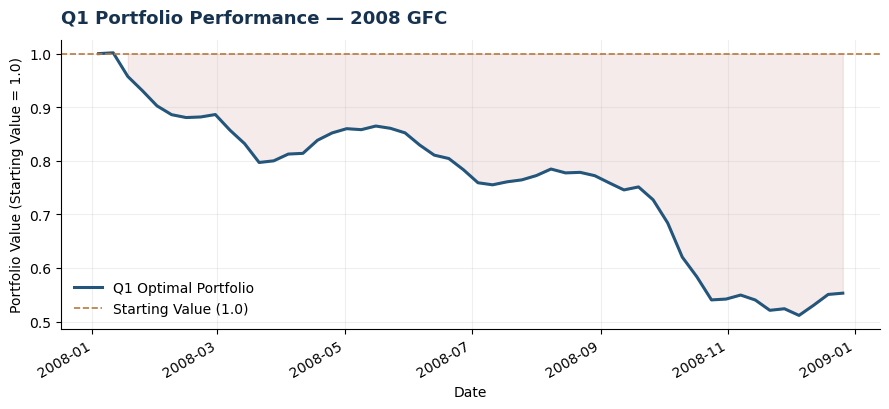

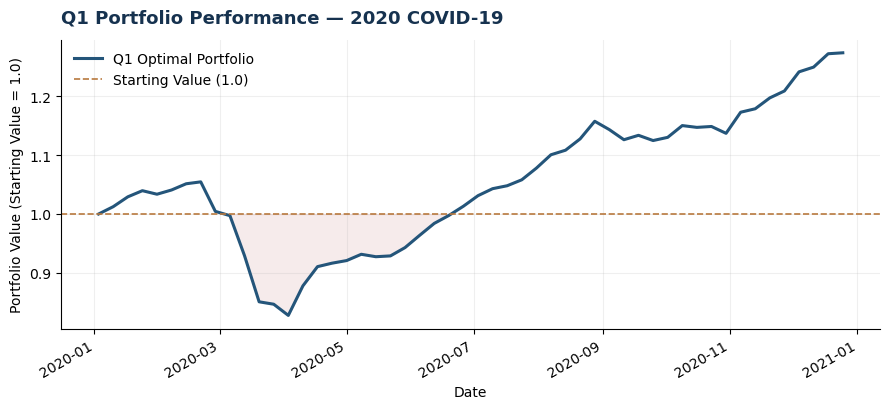

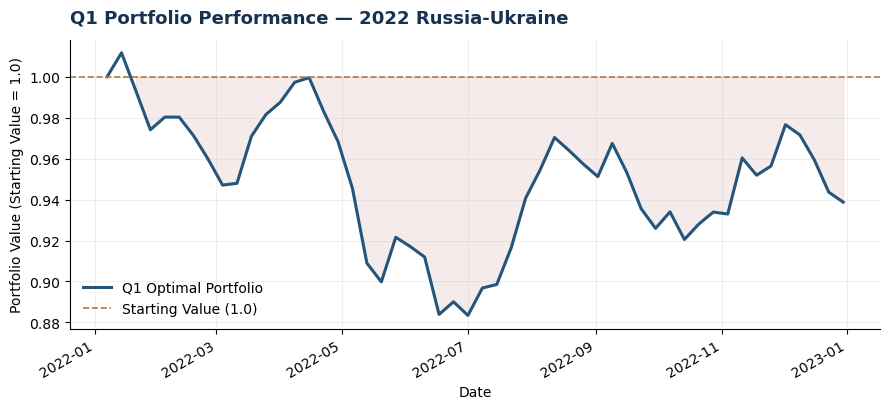

Saved charts:
{'2008 GFC': 'performance_2008_gfc.png', '2020 COVID-19': 'performance_2020_covid_19.png', '2022 Russia-Ukraine': 'performance_2022_russia_ukraine.png'}


In [97]:

# Create consistent performance line charts for all three crises

crisis_periods = {
    "2008 GFC": ("2008-01-01", "2008-12-31"),
    "2020 COVID-19": ("2020-01-01", "2020-12-31"),
    "2022 Russia-Ukraine": ("2022-01-01", "2022-12-31")
}

crisis_chart_files = {}

for name, (start, end) in crisis_periods.items():

    period_returns = master_returns_clean.loc[start:end]

    # Calculate Q1 portfolio weekly returns
    portfolio_returns = (
        period_returns[q1_portfolio.index]
        .mul(q1_portfolio, axis=1)
        .sum(axis=1)
    )

    # Start at 1.0 at the beginning of each crisis period
    growth = (1 + portfolio_returns).cumprod()
    growth = growth / growth.iloc[0]

    fig, ax = plt.subplots(figsize=(9, 4.2))

    ax.plot(
        growth.index, growth.values,
        color="#24557A", linewidth=2.2,
        label="Q1 Optimal Portfolio"
    )

    ax.axhline(
        1.0, color="#B8793E",
        linestyle="--", linewidth=1.2,
        label="Starting Value (1.0)"
    )

    ax.fill_between(
        growth.index, growth.values, 1.0,
        where=(growth.values < 1.0),
        color="#B85C5C", alpha=0.12
    )

    ax.set_title(
        f"Q1 Portfolio Performance — {name}",
        loc="left", fontsize=13, fontweight="bold",
        color="#16324F", pad=12
    )

    ax.set_ylabel("Portfolio Value (Starting Value = 1.0)")
    ax.set_xlabel("Date")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, loc="best")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.autofmt_xdate()
    plt.tight_layout()

    filename = name.lower().replace(" ", "_").replace("-", "_")
    filename = f"performance_{filename}.png"

    fig.savefig(filename, dpi=250, bbox_inches="tight")
    crisis_chart_files[name] = filename
    plt.show()
    plt.close(fig)

print("Saved charts:")
print(crisis_chart_files)


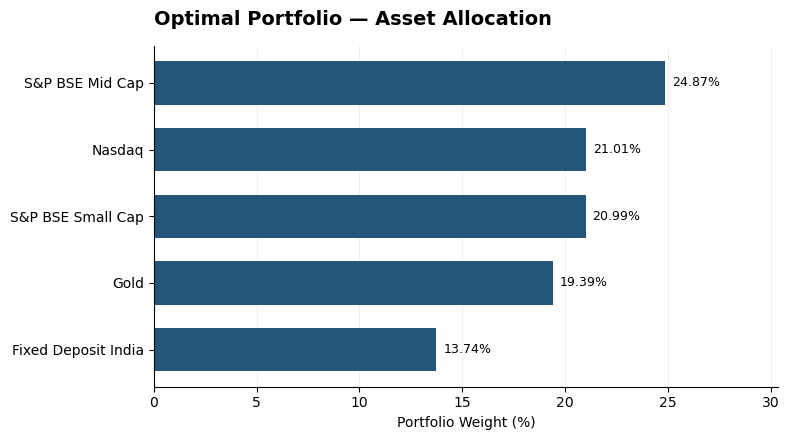

In [78]:
# Asset allocation chart for the factsheet

allocation = q1_allocation.copy()

allocation.columns = ["Asset", "Weight (%)"]
allocation = allocation.sort_values("Weight (%)", ascending=True)

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.barh(
    allocation["Asset"],
    allocation["Weight (%)"],
    color="#24557A",
    height=0.65
)

ax.bar_label(bars, fmt="%.2f%%", padding=5, fontsize=9)

ax.set_title(
    "Optimal Portfolio — Asset Allocation",
    fontsize=14,
    fontweight="bold",
    loc="left",
    pad=15
)

ax.set_xlabel("Portfolio Weight (%)")
ax.set_xlim(0, allocation["Weight (%)"].max() * 1.22)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [79]:
# Crisis performance comparison

crisis = crisis_performance.copy()

print("Columns available:", crisis.columns.tolist())
display(crisis)

Columns available: ['Unnamed: 0', '2008 GFC', '2020 COVID', '2022 Russia-Ukraine']


,Unnamed: 0,2008 GFC,2020 COVID,2022 Russia-Ukraine
0,Q1 Portfolio Return (%),-41.43,28.78,-6.09
1,Annualized Volatility (%),20.08,16.54,10.87


In [80]:
# Inspect the crisis performance table before plotting

print(crisis_performance.to_string(index=False))

               Unnamed: 0  2008 GFC  2020 COVID  2022 Russia-Ukraine
  Q1 Portfolio Return (%)    -41.43       28.78                -6.09
Annualized Volatility (%)     20.08       16.54                10.87


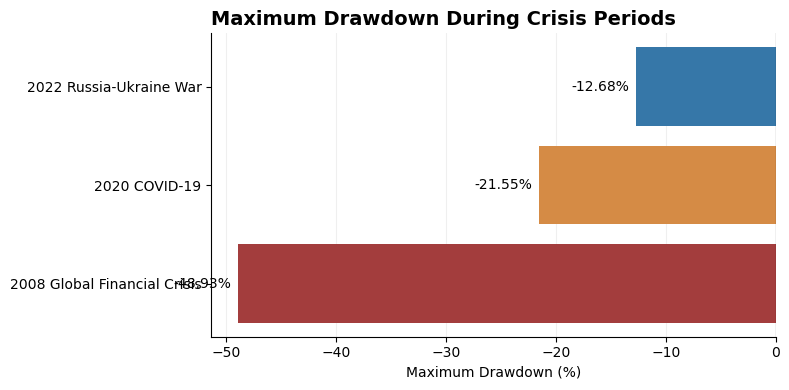

In [81]:
# Crisis maximum drawdown chart

drawdown = pd.Series({
    "2008 Global Financial Crisis": -48.93,
    "2020 COVID-19": -21.55,
    "2022 Russia-Ukraine War": -12.68
}, name="Maximum Drawdown (%)")

fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.barh(
    drawdown.index,
    drawdown.values,
    color=["#A33D3D", "#D58B45", "#3677A8"]
)

ax.bar_label(bars, fmt="%.2f%%", padding=5)
ax.set_title(
    "Maximum Drawdown During Crisis Periods",
    loc="left",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Maximum Drawdown (%)")
ax.axvline(0, color="black", linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [82]:
# Load detailed data for the factsheet

asset_statistics = pd.read_excel(
    excel_file,
    sheet_name="Asset Statistics",
    index_col=0
)

correlation_matrix = pd.read_excel(
    excel_file,
    sheet_name="Correlation Matrix",
    index_col=0
)

gfc_allocation = pd.read_excel(
    excel_file,
    sheet_name="2008 GFC Portfolio",
    index_col=0
)

covid_allocation = pd.read_excel(
    excel_file,
    sheet_name="2020 COVID Portfolio",
    index_col=0
)

ukraine_allocation = pd.read_excel(
    excel_file,
    sheet_name="2022 Ukraine Portfolio",
    index_col=0
)

print("ASSET STATISTICS")
display(asset_statistics)

print("STRESS PORTFOLIO ALLOCATIONS")
display(pd.concat(
    {
        "2008 GFC": gfc_allocation,
        "2020 COVID": covid_allocation,
        "2022 Russia-Ukraine": ukraine_allocation
    },
    axis=1
))

print("FORWARD PERFORMANCE")
display(forward_performance)

ASSET STATISTICS


,Annual Return %,Annual Volatility %
S&P 500,10.925156,18.063662
Nasdaq,15.490321,20.423716
Nikkei,9.928282,21.979853
BSE Sensex,10.565639,19.477462
S&P BSE Mid Cap,14.664109,22.131456
S&P BSE Small Cap,15.865544,25.590855
FTSE 100,4.372384,17.122166
Hang Seng,2.936447,22.159236
S&P/ASX 200,3.233473,15.786683
Gold,11.697015,17.695845


STRESS PORTFOLIO ALLOCATIONS


,2008 GFC,2020 COVID,2022 Russia-Ukraine
,Weight (%),Weight (%),Weight (%)
S&P 500,8.84,12.58,NaN
FTSE 100,18.05,8.03,8.60
Gold,22.62,8.00,12.96
US 10-Year Benchmark,22.29,NaN,NaN
India 10-Year Benchmark,20.95,5.07,NaN
Fixed Deposit India,7.23,NaN,2.34
Nasdaq,NaN,17.62,NaN
Nikkei,NaN,11.32,15.82
S&P BSE Mid Cap,NaN,12.97,14.70


FORWARD PERFORMANCE


,Unnamed: 0,2008 GFC Stress Portfolio,2020 COVID Stress Portfolio,2022 Ukraine Stress Portfolio
0,Subsequent Period Return (%),32.43,16.78,27.70
1,Annualized Volatility (%),7.32,11.35,11.38


In [84]:
print("Columns:", asset_statistics.columns.tolist())
display(asset_statistics.head())

Columns: ['Annual Return %', 'Annual Volatility %']


,Annual Return %,Annual Volatility %
S&P 500,10.925156,18.063662
Nasdaq,15.490321,20.423716
Nikkei,9.928282,21.979853
BSE Sensex,10.565639,19.477462
S&P BSE Mid Cap,14.664109,22.131456


In [85]:
print(asset_statistics.columns.tolist())

['Annual Return %', 'Annual Volatility %']


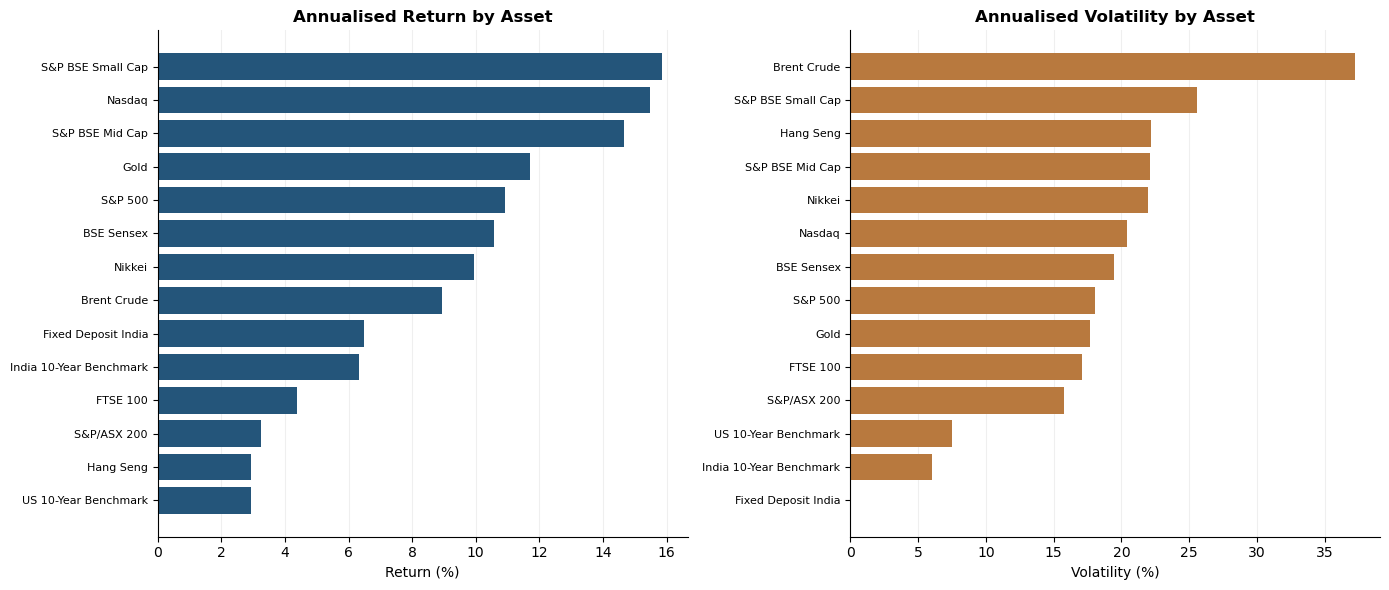

In [86]:
stats = asset_statistics.copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Annualised returns
returns = stats["Annual Return %"].sort_values()
axes[0].barh(returns.index, returns.values, color="#24557A")
axes[0].set_title("Annualised Return by Asset", fontweight="bold")
axes[0].set_xlabel("Return (%)")
axes[0].grid(axis="x", alpha=0.2)

# Annualised volatility
volatility = stats["Annual Volatility %"].sort_values()
axes[1].barh(volatility.index, volatility.values, color="#B8793E")
axes[1].set_title("Annualised Volatility by Asset", fontweight="bold")
axes[1].set_xlabel("Volatility (%)")
axes[1].grid(axis="x", alpha=0.2)

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="y", labelsize=8)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("asset_risk_return.png", dpi=250, bbox_inches="tight")
plt.show()

In [87]:
# Crisis and subsequent-period performance comparison

crisis_df = crisis_performance.copy()
forward_df = forward_performance.copy()

print("CRISIS PERFORMANCE")
display(crisis_df)

print("SUBSEQUENT-PERIOD PERFORMANCE")
display(forward_df)

CRISIS PERFORMANCE


,Unnamed: 0,2008 GFC,2020 COVID,2022 Russia-Ukraine
0,Q1 Portfolio Return (%),-41.43,28.78,-6.09
1,Annualized Volatility (%),20.08,16.54,10.87


SUBSEQUENT-PERIOD PERFORMANCE


,Unnamed: 0,2008 GFC Stress Portfolio,2020 COVID Stress Portfolio,2022 Ukraine Stress Portfolio
0,Subsequent Period Return (%),32.43,16.78,27.70
1,Annualized Volatility (%),7.32,11.35,11.38


In [88]:
# Inspect the crisis and forward-performance columns

print("Crisis columns:", crisis_df.columns.tolist())
print("Forward-performance columns:", forward_df.columns.tolist())

display(crisis_df)
display(forward_df)

Crisis columns: ['Unnamed: 0', '2008 GFC', '2020 COVID', '2022 Russia-Ukraine']
Forward-performance columns: ['Unnamed: 0', '2008 GFC Stress Portfolio', '2020 COVID Stress Portfolio', '2022 Ukraine Stress Portfolio']


,Unnamed: 0,2008 GFC,2020 COVID,2022 Russia-Ukraine
0,Q1 Portfolio Return (%),-41.43,28.78,-6.09
1,Annualized Volatility (%),20.08,16.54,10.87


,Unnamed: 0,2008 GFC Stress Portfolio,2020 COVID Stress Portfolio,2022 Ukraine Stress Portfolio
0,Subsequent Period Return (%),32.43,16.78,27.70
1,Annualized Volatility (%),7.32,11.35,11.38


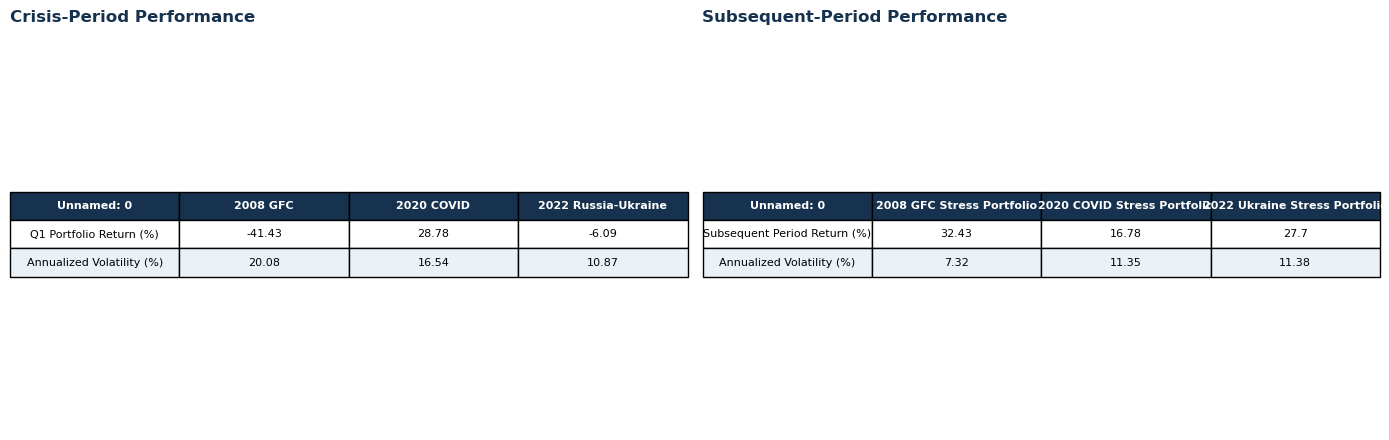

In [89]:
# Format the crisis performance tables for the factsheet

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
fig.patch.set_facecolor("white")

for ax, df, title in [
    (axes[0], crisis_df, "Crisis-Period Performance"),
    (axes[1], forward_df, "Subsequent-Period Performance")
]:
    ax.axis("off")
    ax.set_title(
        title, loc="left", fontsize=12,
        fontweight="bold", color="#16324F", pad=12
    )

    table_data = [
        [str(col) for col in df.columns]
    ] + [
        [str(value) for value in row]
        for row in df.values
    ]

    table = ax.table(
        cellText=table_data[1:],
        colLabels=table_data[0],
        loc="center",
        cellLoc="center"
    )

    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1, 1.5)

    for (r, c), cell in table.get_celld().items():
        if r == 0:
            cell.set_facecolor("#16324F")
            cell.set_text_props(color="white", weight="bold")
        else:
            cell.set_facecolor("#EAF1F7" if r % 2 == 0 else "white")

plt.tight_layout()
plt.savefig("crisis_recovery_tables.png", dpi=250, bbox_inches="tight")
plt.show()

In [94]:
%pip install reportlab

Note: you may need to restart the kernel to use updated packages.


In [95]:

from reportlab.lib import colors
from reportlab.lib.pagesizes import A4, landscape
from reportlab.lib.units import mm
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image,
    Table, TableStyle, PageBreak
)
import os
import numpy as np

pdf_file = "SAPM_Detailed_Factsheet.pdf"
navy = colors.HexColor("#16324F")
blue = colors.HexColor("#24557A")
light_blue = colors.HexColor("#EAF1F7")

styles = getSampleStyleSheet()
title_style = ParagraphStyle(
    "FactTitle", parent=styles["Title"],
    fontSize=19, textColor=colors.white,
    alignment=0, leading=23
)
section_style = ParagraphStyle(
    "FactSection", parent=styles["Heading2"],
    fontSize=12, textColor=navy,
    spaceBefore=8, spaceAfter=5
)
small_style = ParagraphStyle(
    "FactSmall", parent=styles["BodyText"],
    fontSize=8, leading=11
)

doc = SimpleDocTemplate(
    pdf_file, pagesize=landscape(A4),
    rightMargin=12*mm, leftMargin=12*mm,
    topMargin=10*mm, bottomMargin=10*mm
)
story = []

def make_table(df, width=255*mm):
    data = [[str(c) for c in df.columns]]
    for row in df.values:
        data.append([
            f"{v:.2f}" if isinstance(v, (int, float, np.number))
            else str(v)
            for v in row
        ])
    col_width = width / max(1, len(df.columns))
    t = Table(data, colWidths=[col_width]*len(df.columns), repeatRows=1)
    t.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), navy),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("FONTSIZE", (0, 0), (-1, -1), 7),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.lightgrey),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1),
         [colors.white, light_blue]),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("TOPPADDING", (0, 0), (-1, -1), 5),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
    ]))
    return t

# PAGE 1: Portfolio overview
banner = Table([[
    Paragraph("PORTFOLIO MANAGEMENT &amp; CRISIS BACKTESTING", title_style),
    Paragraph(
        "SAPM | IMT Ghaziabad<br/>Historical portfolio optimisation",
        ParagraphStyle(
            "BannerSubtitle", parent=styles["Normal"],
            fontSize=9, textColor=colors.white, alignment=2
        )
    )
]], colWidths=[175*mm, 85*mm])

banner.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, -1), navy),
    ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
    ("LEFTPADDING", (0, 0), (-1, -1), 9),
    ("RIGHTPADDING", (0, 0), (-1, -1), 9),
    ("TOPPADDING", (0, 0), (-1, -1), 10),
    ("BOTTOMPADDING", (0, 0), (-1, -1), 10),
]))
story += [banner, Spacer(1, 4*mm)]

story.append(Paragraph("01 | Optimal Portfolio Allocation", section_style))
story.append(make_table(q1_allocation))
story.append(Spacer(1, 3*mm))

story.append(Paragraph("02 | Portfolio Performance", section_style))
story.append(make_table(q1_performance, width=130*mm))
story.append(Spacer(1, 3*mm))

if os.path.exists("asset_risk_return.png"):
    story.append(Paragraph("03 | Asset-Level Risk and Return", section_style))
    story.append(Image("asset_risk_return.png", width=225*mm, height=95*mm))

story.append(PageBreak())

# PAGE 2: Crisis analysis
story.append(Paragraph("04 | Crisis Backtesting", title_style))
story.append(Spacer(1, 4*mm))

if os.path.exists("crisis_drawdown.png"):
    story.append(Image("crisis_drawdown.png", width=130*mm, height=48*mm))

story.append(Paragraph("Crisis-Period Performance", section_style))
story.append(make_table(crisis_df))
story.append(Spacer(1, 4*mm))

story.append(Paragraph("Subsequent-Period Performance", section_style))
story.append(make_table(forward_df))
story.append(Spacer(1, 4*mm))

story.append(Paragraph("05 | Stress Portfolio Comparison", section_style))
story.append(make_table(final_results.reset_index()))

story.append(Spacer(1, 4*mm))
story.append(Paragraph("Methodology and Limitations", section_style))
story.append(Paragraph(
    "The initial portfolio was selected using a maximum-Sharpe-ratio "
    "approach subject to allocation constraints. Stress portfolios "
    "optimised using returns from the same crisis year are ex-post "
    "historical stress tests and involve hindsight. Currency effects "
    "are ignored as instructed. The fixed-deposit return and risk-free "
    "rate are project assumptions. Historical performance is not a forecast.",
    small_style
))

doc.build(story)
print("PDF created:", os.path.abspath(pdf_file))


PDF created: C:\Users\Dell\anaconda_projects\a63ee5b9-a7c0-495a-983b-d924e1e2cac3\SAPM_Detailed_Factsheet.pdf


In [96]:
import os
print(os.path.abspath("SAPM_Detailed_Factsheet.pdf"))

C:\Users\Dell\anaconda_projects\a63ee5b9-a7c0-495a-983b-d924e1e2cac3\SAPM_Detailed_Factsheet.pdf
